# Decomposing goal-directedness and directional precision in sensory-deprived echolocating bats during homing

This notebook revisits the free-flying bat homing data of A. Goldshtein et al., "Acoustic cognitive map–based navigation in echolocating bats," *Science* **386**(6721), 561-567 (2024); [doi:10.1126/science.adn6269](https://doi.org/10.1126/science.adn6269) - echolocating bats translocated over kilometer scales and tracked back to a known goal. The original study found that bats typically do home successfully even under sensory deprivation, consistent with echolocation being a sufficient and robust navigation modality. The question revisited here is whether that deprivation nonetheless produces detectable changes in **goal-relative orientation** (directional bias and/or directional precision).

Each flight is a GPS track recorded with an on-animal tag. We reduce each track to a sequence of
fixed-length movement **steps**, compute a heading per step, and express that heading **relative
to the instantaneous direction toward the animal's known destination** (its roost or the Agamon–Hula lake region). On this goal-relative scale, a step aimed straight at the goal is
near $0^\circ$ and a step heading away is near $\pm180^\circ$, so fitted von Mises parameters map
directly onto goal-directed travel.

**Why a mixture:** stepwise headings in these tracks are multimodal. A bat may wander before
committing to goal-directed travel, and the original study had to split trajectories into a
localization phase and a homing phase using *post-treatment* features (straightness,
distance-to-goal). Selecting on such features can entangle treatment effects with the selection
rule. To avoid that, the main analysis below fits a **von Mises--Uniform mixture (vMU)**: each step
is drawn either from a directed von Mises component (goal-directed "exploitation") or from an
undirected component (wandering "exploration"), with treatment and per-animal (tag) random
effects. This separates trajectory structure from treatment comparisons while using the **full**
trajectory, with no post-treatment filtering.

The notebook also fits a simpler **single von Mises treatment model** (brms) first, so the vMU
result can be read against a non-mixed baseline, and compares the two out-of-sample (PSIS-LOO
ELPD).


## Setup

Select the R (`ir`) kernel and follow the [R setup](../getting-started-r.md)
page for the compiler and kernel prerequisites. Run the cells in order.


In [1]:
required <- c("brms", "posterior", "loo", "circular", "readxl", "sf", "geosphere", "Matrix", "ggplot2", "ragg", "IRdisplay", "patchwork")
missing <- required[!vapply(required, requireNamespace, logical(1), quietly = TRUE)]
if (length(missing)) {
  install.packages(missing, repos = "https://cloud.r-project.org")
}

if (!requireNamespace("cmdstanr", quietly = TRUE)) {
  install.packages("cmdstanr",
    repos = c("https://stan-dev.r-universe.dev", "https://cloud.r-project.org"))
}
cmdstan_ok <- tryCatch(dir.exists(as.character(cmdstanr::cmdstan_path())),
  error = function(e) FALSE)
if (!cmdstan_ok) cmdstanr::install_cmdstan()


In [2]:
versions <- c(R = as.character(getRversion()),
  vapply(c("brms", "posterior", "loo", "circular", "readxl", "sf", "geosphere", "Matrix", "ggplot2", "ragg", "IRdisplay", "patchwork", "cmdstanr"),
    function(p) as.character(packageVersion(p)), character(1)))
versions


R          brms     posterior           loo      circular 
      "4.5.3"      "2.23.0"       "1.7.1" "2.10.1.9000"       "0.5.2" 
       readxl            sf     geosphere        Matrix       ggplot2 
      "1.6.0"       "1.1.3"       "1.6.8"       "1.7.6"       "4.0.3" 
         ragg     IRdisplay     patchwork      cmdstanr 
      "1.5.2"         "1.1"       "1.3.2"       "0.9.0"

In [3]:
suppressPackageStartupMessages({
  library(brms)
  library(posterior)
  library(loo)
  library(circular)
  library(readxl)
  library(sf)
  library(geosphere)
  library(Matrix)
  library(ggplot2)
  library(patchwork)
})


In [4]:
repo_root <- if (file.exists(file.path("..", "R", "unwrap_family.R"))) {
  ".."
} else if (file.exists(file.path("R", "unwrap_family.R"))) {
  "."
} else {
  stop("Run from notebooks_r/ or the repository root.")
}

source(file.path(repo_root, "R", "unwrap_family.R"))
source(file.path(repo_root, "R", "unwrap_functions.R"))


Loading required package: cmdstanr



This is cmdstanr version 0.9.0



- CmdStanR documentation and vignettes: mc-stan.org/cmdstanr



- CmdStan path: /home/jake/.cmdstan/cmdstan-2.40.0



- CmdStan version: 2.40.0



In [5]:
FIG_DIR <- file.path(repo_root, "figures", "goldshtein_bats")
dir.create(FIG_DIR, recursive = TRUE, showWarnings = FALSE)
# Render headless PNGs with ragg; keep archival vector PDFs alongside them.

show_figure <- function(plot, name, width, height, res = 110) {
  file <- file.path(FIG_DIR, paste0(name, ".png"))
  ragg::agg_png(file, width = width, height = height, units = "in",
                res = res)
  print(plot)
  invisible(dev.off())
  IRdisplay::display_png(file = file)
  invisible(NULL)
}

theme_set(theme_minimal(base_size = 12))
save_figure <- function(plot, name, width = 8, height = 5) {
  ggsave(file.path(FIG_DIR, paste0(name, ".pdf")), plot, width = width, height = height)
  show_figure(plot, name, width, height)
}


In [6]:
SEED <- 123
quick_run <- Sys.getenv("UNWRAP_R_QUICK") == "1"
CHAINS <- if (quick_run) 2L else 4L
ITER <- if (quick_run) 3000L else 4000L
WARMUP <- if (quick_run) 1500L else 2000L
# These are local execution budgets, not convergence claims. Hard diagnostic
# gates below apply to both budgets; increase sampling if they fail.


In [7]:
wrap <- function(x) atan2(sin(x), cos(x))
circ_mean <- function(x) atan2(mean(sin(x)), mean(cos(x)))
resultant <- function(x) Mod(mean(exp(1i * x)))
softplus_stable <- function(x) pmax(x, 0) + log1p(exp(-abs(x)))
log1p_exp <- softplus_stable
A1_safe <- function(k) {
  z <- besselI(k, 1, expon.scaled = TRUE) / besselI(k, 0, expon.scaled = TRUE)
  if (!is.null(dim(k))) dim(z) <- dim(k)
  z
}
vm_logpdf <- function(y, mu, kappa) {
  kappa * (cos(y - mu) - 1) - log(2 * pi) - log(besselI(kappa, 0, expon.scaled = TRUE))
}
hdi <- function(x, prob = 0.95) {
  x <- sort(as.numeric(x))
  stopifnot(length(x) > 1L, all(is.finite(x)))
  gap <- min(length(x) - 1L, floor(prob * length(x)))
  ii <- seq_len(length(x) - gap)
  j <- ii[which.min(x[ii + gap] - x[ii])]
  c(low = x[j], high = x[j + gap])
}
interval <- function(x, angular = FALSE, prob = 0.95) {
  m <- if (angular) circ_mean(x) else mean(x)
  z <- if (angular) m + wrap(x - m) else x
  c(mean = m, hdi(z, prob))
}
vmu <- function(m) circular::circular(
    m, units = "radians", template = "none", modulo = "2pi")
vm_ctrl <- list(units = "radians", template = "none", modulo = "2pi")
draw_vm <- function(mu, kappa) {
  wrap(as.numeric(circular::rvonmises(1, mu = vmu(mu), kappa = kappa,
                                     control.circular = vm_ctrl)))
}
draw_matrix <- function(fit, parameters) {
  as.data.frame(posterior::as_draws_df(posterior::subset_draws(
    posterior::as_draws_array(fit), variable = parameters)))
}

diagnose_fit <- function(fit, angular = character(), parameters = NULL) {
  # Probe exactly the flags retained by this brms/backend combination.
  divergences <- tryCatch({
    samples <- fit$fit@sim$samples
    if (is.null(samples) || !length(samples)) {
      NA_real_
    } else {
      div_flags <- lapply(samples, function(ch) ch[["divergent"]])
      if (any(vapply(div_flags, is.null, logical(1)))) NA_real_
      else sum(unlist(div_flags))
    }
  }, error = function(e) NA_real_)
  if (is.na(divergences)) {
    cat("Divergences: not retained in this fit object (see R-hat/ESS below).\n")
  } else {
    cat("Divergences:", divergences, "\n")
    stopifnot(divergences == 0)
  }
  a <- posterior::as_draws_array(fit)
  if (is.null(parameters)) {
    parameters <- posterior::variables(a)
    parameters <- parameters[grepl("^(b_|sd_|r_|kmu_)", parameters)]
  }
  stopifnot(length(parameters) > 0L)
  summary_frame <- do.call(rbind, lapply(parameters, function(p) {
    x <- as.matrix(a[, , p])
    # as_draws_array keeps the draws_array class, whose [ method does not
    # drop the parameter slice, so x is retained as one long column
    # (draws x chains flattened); the rhat/ESS calls below are written
    # for that layout (as in the P1 notebooks).
    stopifnot(all(is.finite(x)))
    is_angle <- p %in% angular
    z <- if (is_angle) wrap(x - circ_mean(x)) else x
    data.frame(parameter = p,
      mean = if (is_angle) circ_mean(x) else mean(x),
      sd = if (is_angle) sqrt(-2 * log(min(1, resultant(x)))) else sd(as.numeric(x)),
      rhat = if (is_angle) Rhat_unwrap(x, method = "sine") else posterior::rhat(x),
      ess_bulk = posterior::ess_bulk(z), row.names = NULL)
  }))
  print(summary_frame)
  stopifnot(all(is.finite(summary_frame$rhat)), all(summary_frame$rhat < 1.01),
    all(is.finite(summary_frame$ess_bulk)), all(summary_frame$ess_bulk > 400))
  summary_frame
}
trace_plot <- function(fit, parameters, angular = character()) {
  d <- draw_matrix(fit, parameters)
  long <- do.call(rbind, lapply(parameters, function(p) {
    x <- d[[p]]
    if (p %in% angular) x <- wrap(x - circ_mean(x))
    data.frame(parameter = p, value = x, iteration = d[[".iteration"]],
               chain = factor(d[[".chain"]]))
  }))
  ggplot(long, aes(iteration, value, colour = chain, group = chain)) +
    geom_line(linewidth = 0.25, alpha = 0.6) +
    facet_wrap(~ parameter, scales = "free_y", ncol = 2) +
    labs(x = "retained iteration", y = "draw (angular traces centered)") +
    theme(legend.position = "bottom")
}


## 1. Load the data

Per-tag metadata and the raw track file. `meta_df` carries the treatment assignment and the
destination flags; `raw_track_df` carries the georeferenced track per tag.


In [8]:
# A supplied root may be a data checkout or the directory holding the files.
data_override <- Sys.getenv("UNWRAP_DATA_ROOT", unset = "")
data_root <- if (nzchar(data_override)) data_override else file.path(repo_root, "unwrap-data")
file_names <- c("all_bats_info.xls", "dataAll_trackDest.xls", "agamon_hula_lake_outline.geojson")
find_bat_files <- function(root) {
  candidates <- c(root, file.path(root, "goldshtein_bats"), file.path(root, "goldschtein_bats"))
  good <- vapply(candidates, function(p) all(file.exists(file.path(p, file_names))), logical(1))
  if (any(good)) candidates[which(good)[1]] else NULL
}
data_dir <- find_bat_files(data_root)
if (is.null(data_dir)) {
  if (nzchar(data_override)) stop("UNWRAP_DATA_ROOT does not contain the three published bat files.")
  if (!dir.exists(data_root)) {
    status <- system2("git", c("clone", "--depth", "1", "--filter=blob:none", "--sparse",
      "https://github.com/jgraving/unwrap-data.git", shQuote(data_root)))
    stopifnot(status == 0L)
  }
  # The published directory currently includes an extra 'c'; accept either
  # spelling locally while preserving the filenames and scientific dataset.
  status <- system2("git", c("-C", shQuote(data_root), "sparse-checkout", "add", "goldschtein_bats"))
  stopifnot(status == 0L)
  data_dir <- find_bat_files(data_root)
}
stopifnot(!is.null(data_dir))
# Legacy BIFF .xls files, explicitly read with readxl::read_xls (not xlsx).
meta_df <- as.data.frame(readxl::read_xls(file.path(data_dir, "all_bats_info.xls")))
raw_track_df <- as.data.frame(readxl::read_xls(file.path(data_dir, "dataAll_trackDest.xls")))
cat("Metadata:", nrow(meta_df), "rows x", ncol(meta_df), "columns\n")
cat("Raw tracks:", nrow(raw_track_df), "rows x", ncol(raw_track_df), "columns\n")
stopifnot(nrow(meta_df) == 67L, ncol(meta_df) == 56L,
          nrow(raw_track_df) == 28350L, ncol(raw_track_df) == 17L)
head(raw_track_df)


Metadata: 67 rows x 56 columns


Raw tracks: 28350 rows x 17 columns


,tag,time,x,y,lon,lat,alt,si,distance,speed,flightAngle,turningAngle,distDeparture,distDest,flightAngDiffDest,afterLocalization,illumination
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,7602,738609,255310.9,781769.7,35.58867,33.13064,70,NA,NA,NA,57.21171,NA,584.0712,2530.181,106.157718,0,0
2,7602,738609,255426.6,781844.7,35.58991,33.13132,70,0.6214775,137.86512,1.077139,73.37843,-1.233640e-05,466.7111,2571.958,92.942905,1,0
3,7602,738609,255451.9,781852.4,35.59018,33.13138,70,0.6310361,26.48756,13.243783,73.37842,8.813593e+01,450.8914,2573.454,93.532022,1,0
4,7602,738609,255477.3,781860.1,35.59046,33.13145,70,0.6402230,26.48756,13.243783,161.51435,3.713325e+01,436.1079,2575.221,5.984448,1,0
5,7602,738609,255484.5,781838.7,35.59053,33.13126,70,0.6490448,22.56382,11.281912,198.64760,2.007633e-05,454.9129,2552.781,-31.095961,1,0
6,7602,738609,255480.8,781827.5,35.59049,33.13116,70,0.6575115,11.77235,5.886178,198.64762,2.007464e-05,466.6518,2542.708,-31.233008,1,0


## 2. Spatially resample to fixed step length

`rediscretize_latlon_parallel` resamples each tag's lat/lon trajectory to a **constant step length**
(60 m) along-track, computing step headings and distances. Gaps in the raw track (a jump larger than
`gap_factor \times spacing_m`, or a time gap larger than `gap_time_s`) split the track into
contiguous `segment_id`s, and the first resampled row after a gap is flagged `gap_before=1`. Working
with fixed step lengths (rather than variable GPS fix intervals) is what lets us treat each step's
bearing as one circular observation and keeps distance along-track `s_along_m` well defined.


In [9]:
resample_segment <- function(g, segment_id) {
  singleton <- function() data.frame(tag = g$tag[1], time = g$time[1],
    lat = g$lat[1], lon = g$lon[1], s_along_m = 0,
    segment_id = segment_id, gap_before = as.integer(segment_id > 0L),
    afterLocalization = g$afterLocalization[1])
  if (nrow(g) < 2L) return(singleton())
  p0 <- as.matrix(g[-nrow(g), c("lon", "lat")])
  p1 <- as.matrix(g[-1L, c("lon", "lat")])
  lengths <- geosphere::distGeo(p0, p1)
  azimuth <- geosphere::bearing(p0, p1)
  lengths[!is.finite(lengths) | lengths <= 0] <- 0
  cumulative <- c(0, cumsum(lengths))
  total <- tail(cumulative, 1)
  if (total <= 0) return(singleton())
  targets <- seq(0, floor((total + 1e-9) / 60) * 60, by = 60)
  # findInterval reproduces searchsorted(..., side="right") - 1.
  index <- pmin(length(lengths), pmax(1L, findInterval(targets, cumulative)))
  fraction <- ifelse(lengths[index] > 0,
    (targets - cumulative[index]) / pmax(lengths[index], .Machine$double.eps), 0)
  fraction <- pmin(1, pmax(0, fraction))
  xy <- geosphere::destPoint(as.matrix(g[index, c("lon", "lat")]),
                            azimuth[index], fraction * lengths[index])
  out <- data.frame(tag = g$tag[1],
    time = (1 - fraction) * g$time[index] + fraction * g$time[index + 1L],
    lat = xy[, 2], lon = xy[, 1], s_along_m = targets,
    segment_id = segment_id, gap_before = 0L,
    afterLocalization = ifelse(fraction >= 0.5,
      g$afterLocalization[index + 1L], g$afterLocalization[index]))
  if (segment_id > 0L) out$gap_before[1] <- 1L
  out
}
resample_tag <- function(g) {
  g <- g[order(g$time), ]
  g <- g[is.finite(g$lat) & is.finite(g$lon) & is.finite(g$time), ]
  stopifnot(nrow(g) > 0L)
  if (nrow(g) < 2L) return(resample_segment(g, 0L))
  d <- geosphere::distGeo(as.matrix(g[-nrow(g), c("lon", "lat")]),
                          as.matrix(g[-1L, c("lon", "lat")]))
  segment <- cumsum(c(0L, as.integer(d > 600 | diff(g$time) > 120 / 86400)))
  do.call(rbind, lapply(unique(segment), function(s) resample_segment(g[segment == s, ], s)))
}
raw_track_df$afterLocalization[is.na(raw_track_df$afterLocalization)] <- 0L
rediscretized <- do.call(rbind, lapply(split(raw_track_df, raw_track_df$tag), resample_tag))
rediscretized <- rediscretized[order(rediscretized$tag, rediscretized$time), ]
rownames(rediscretized) <- NULL
cat("Resampled rows:", nrow(rediscretized), "tags:", length(unique(rediscretized$tag)),
    "gap markers:", sum(rediscretized$gap_before), "\n")
stopifnot(nrow(rediscretized) == 5072L, length(unique(rediscretized$tag)) == 67L,
          sum(rediscretized$gap_before) == 24L)


Resampled rows: 5072 tags: 67 gap markers: 24 


### Per-tag metadata + destination label

Collapse the metadata to one row per tag, coerce the destination flags to 0/1, and build a
`destination` label: `Roost` (flyHome) vs `Agamon` (flyAgamon, the Kinneret/lake region) vs
Unknown. The per-tag metadata are merged back onto the resampled tracks so every step knows its
treatment and goal.


In [10]:
to_flag <- function(x) {
  if (is.logical(x)) return(as.integer(replace(x, is.na(x), FALSE)))
  z <- tolower(trimws(as.character(x)))
  as.integer(z %in% c("1", "true", "t", "yes"))
}
stopifnot(!anyDuplicated(meta_df$tag))
idx <- match(rediscretized$tag, meta_df$tag)
stopifnot(!anyNA(idx))
track_w_treat <- cbind(rediscretized,
  meta_df[idx, c("treatment", "treatmentName", "flyHome", "flyAgamon"), drop = FALSE])
track_w_treat$flyHome <- to_flag(track_w_treat$flyHome)
track_w_treat$flyAgamon <- to_flag(track_w_treat$flyAgamon)
track_w_treat$dest <- ifelse(track_w_treat$flyHome == 1 & track_w_treat$flyAgamon == 0, "Home",
  ifelse(track_w_treat$flyAgamon == 1 & track_w_treat$flyHome == 0, "Agamon",
    ifelse(track_w_treat$flyHome == 1 & track_w_treat$flyAgamon == 1, "Ambiguous", "Unknown")))
track_w_treat$destination <- ifelse(track_w_treat$dest == "Home", "Roost", track_w_treat$dest)
table(track_w_treat$treatment, track_w_treat$destination)


   
    Agamon Roost
  1   1398   203
  2    520   693
  3    835   344
  4    361   718

## 3. Goal-relative bearings (distance + bearing to the destination)

For every resampled step, compute:

- its local metric coordinates (`x_m, y_m`, a projected plane around the arena),
- its step `bearing_to_...`/`direction`,
- the **instantaneous direction toward the goal**: for the lake (Agamon) this is the
  negative-gradient of a smoothed-distance (or harmonic) distance field (`-\nabla u`), so the
  "best way to reduce distance" from each point, not just a straight line to a single point; for
  the roost it is the bearing to the roost point,
- the **goal-relative angle** `flightAngDiffDest_{deg,rad}`: the animal's step bearing **relative to**
  that goal direction. This is the circular response used in the models below (0 = aimed at goal).

This is what places every flight on a common circular scale: steps toward the goal lie near $0^\circ$,
steps away near $\pm180^\circ$.


In [11]:
lake <- sf::st_read(file.path(data_dir, "agamon_hula_lake_outline.geojson"), quiet = TRUE)
lake_m <- sf::st_union(sf::st_transform(lake, 32636))
lake_boundary <- sf::st_boundary(lake_m)
roost <- sf::st_sfc(sf::st_point(c(35.584135, 33.112373)), crs = 4326)
roost_m <- sf::st_transform(roost, 32636)
points_m <- sf::st_transform(sf::st_as_sf(track_w_treat, coords = c("lon", "lat"),
                                         crs = 4326, remove = FALSE), 32636)
xy <- sf::st_coordinates(points_m)
track_w_treat$x_m <- xy[, 1]
track_w_treat$y_m <- xy[, 2]

cg_solve <- function(A, b, rtol = 1e-8, maxiter = 3000L) {
  x <- numeric(length(b))
  residual <- b
  direction <- residual
  rr <- sum(residual^2)
  threshold <- rtol^2 * sum(b^2)
  if (rr <= threshold) return(x)
  for (iter in seq_len(maxiter)) {
    product <- as.numeric(A %*% direction)
    step <- rr / sum(direction * product)
    x <- x + step * direction
    residual <- residual - step * product
    next_rr <- sum(residual^2)
    if (next_rr <= threshold) return(x)
    direction <- residual + (next_rr / rr) * direction
    rr <- next_rr
  }
  stop("Harmonic-field conjugate gradient did not converge; inspect the grid.")
}
grid_geometry <- function(x, y, resolution) {
  bb <- sf::st_bbox(lake_m)
  xr <- range(c(x, bb[c("xmin", "xmax")]))
  yr <- range(c(y, bb[c("ymin", "ymax")]))
  margin <- max(1000, 0.1 * max(diff(xr), diff(yr)))
  xs <- xr[1] - margin + (0:ceiling((diff(xr) + 2 * margin) / resolution)) * resolution
  ys <- yr[1] - margin + (0:ceiling((diff(yr) + 2 * margin) / resolution)) * resolution
  g <- expand.grid(x = xs, y = ys)
  pts <- sf::st_as_sf(g, coords = c("x", "y"), crs = 32636)
  # Grid matrices use [y x x]; map from expand.grid's x-fast order.
  inside <- lengths(sf::st_within(pts, lake_m)) > 0L
  mask <- t(matrix(inside, nrow = length(xs), ncol = length(ys)))
  list(xs = xs, ys = ys, mask = mask, resolution = resolution,
       ray_max = sqrt(diff(range(xs))^2 + diff(range(ys))^2))
}
solve_harmonic <- function(mask) {
  nr <- nrow(mask)
  nc <- ncol(mask)
  u <- matrix(1, nr, nc)
  u[mask] <- 0
  u[c(1L, nr), ] <- 1
  u[, c(1L, nc)] <- 1
  free <- !mask
  free[c(1L, nr), ] <- FALSE
  free[, c(1L, nc)] <- FALSE
  where <- which(free)
  if (!length(where)) return(u)
  index <- matrix(0L, nr, nc)
  index[where] <- seq_along(where)
  neighbors <- lapply(c(-1L, 1L, -nr, nr), function(delta) where + delta)
  row_i <- rep(seq_along(where), 4)
  neighbor_index <- unlist(lapply(neighbors, function(j) index[j]), use.names = FALSE)
  neighbor_values <- unlist(lapply(neighbors, function(j) u[j]), use.names = FALSE)
  unknown <- neighbor_index > 0L
  A <- Matrix::sparseMatrix(i = c(seq_along(where), row_i[unknown]),
    j = c(seq_along(where), neighbor_index[unknown]),
    x = c(rep(4, length(where)), rep(-1, sum(unknown))),
    dims = c(length(where), length(where)))
  b <- numeric(length(where))
  for (j in neighbors) b <- b + ifelse(index[j] == 0L, u[j], 0)
  u[where] <- cg_solve(A, b)
  u
}
field_vectors <- function(g, values) {
  nr <- nrow(values)
  nc <- ncol(values)
  dx <- dy <- matrix(0, nr, nc)
  dx[, 2:(nc - 1L)] <- (values[, 3:nc] - values[, 1:(nc - 2L)]) / (2 * g$resolution)
  dy[2:(nr - 1L), ] <- (values[3:nr, ] - values[1:(nr - 2L), ]) / (2 * g$resolution)
  dx[, 1] <- (values[, 2] - values[, 1]) / g$resolution
  dx[, nc] <- (values[, nc] - values[, nc - 1L]) / g$resolution
  dy[1, ] <- (values[2, ] - values[1, ]) / g$resolution
  dy[nr, ] <- (values[nr, ] - values[nr - 1L, ]) / g$resolution
  norm <- sqrt(dx^2 + dy^2)
  g$tx <- -dx / norm
  g$ty <- -dy / norm
  g$tx[norm <= 0] <- NA_real_
  g$ty[norm <= 0] <- NA_real_
  g$values <- values
  g
}
bilinear <- function(F, x, y, g) {
  fx <- (x - g$xs[1]) / g$resolution
  fy <- (y - g$ys[1]) / g$resolution
  ix <- floor(fx) + 1L
  iy <- floor(fy) + 1L
  wx <- fx - floor(fx)
  wy <- fy - floor(fy)
  ix1 <- pmin(ix + 1L, ncol(F))
  iy1 <- pmin(iy + 1L, nrow(F))
  (1 - wx) * (1 - wy) * F[cbind(iy, ix)] +
    wx * (1 - wy) * F[cbind(iy, ix1)] +
    (1 - wx) * wy * F[cbind(iy1, ix)] + wx * wy * F[cbind(iy1, ix1)]
}
harmonic <- grid_geometry(track_w_treat$x_m, track_w_treat$y_m, 20)
harmonic <- field_vectors(harmonic, solve_harmonic(harmonic$mask))
tx <- bilinear(harmonic$tx, track_w_treat$x_m, track_w_treat$y_m, harmonic)
ty <- bilinear(harmonic$ty, track_w_treat$x_m, track_w_treat$y_m, harmonic)
norm <- sqrt(tx^2 + ty^2)
tx <- tx / norm
ty <- ty / norm
lake_direction <- atan2(tx, ty)
ray_distance <- function(i) {
  if (!is.finite(tx[i]) || !is.finite(ty[i])) return(NA_real_)
  origin <- sf::st_sfc(sf::st_point(xy[i, ]), crs = 32636)
  if (lengths(sf::st_intersects(origin, lake_m)) > 0L) return(0)
  end <- xy[i, ] + harmonic$ray_max * c(tx[i], ty[i])
  ray <- sf::st_sfc(sf::st_linestring(rbind(xy[i, ], end)), crs = 32636)
  hit <- sf::st_intersection(ray, lake_m)
  if (!length(hit) || all(sf::st_is_empty(hit))) return(NA_real_)
  min(as.numeric(sf::st_distance(origin, hit)))
}
track_w_treat$dist_to_lake_grad_m <- vapply(seq_len(nrow(track_w_treat)), ray_distance, numeric(1))
roost_xy <- as.numeric(sf::st_coordinates(roost_m)[1, ])
dx_roost <- roost_xy[1] - xy[, 1]
dy_roost <- roost_xy[2] - xy[, 2]
track_w_treat$dist_to_roost_m <- sqrt(dx_roost^2 + dy_roost^2)
track_w_treat$dist_to_lake_m <- as.numeric(sf::st_distance(sf::st_geometry(points_m), lake_boundary))
track_w_treat$dist_to_dest_grad_m <- ifelse(track_w_treat$dest == "Home",
  track_w_treat$dist_to_roost_m, ifelse(track_w_treat$dest == "Agamon",
  track_w_treat$dist_to_lake_grad_m, NA_real_))
track_w_treat$dist_to_dest_m <- ifelse(track_w_treat$dest == "Home",
  track_w_treat$dist_to_roost_m, ifelse(track_w_treat$dest == "Agamon",
    track_w_treat$dist_to_lake_m, NA_real_))
track_w_treat$dx_step_m <- ave(track_w_treat$x_m, track_w_treat$tag,
                              FUN = function(x) c(NA_real_, diff(x)))
track_w_treat$dy_step_m <- ave(track_w_treat$y_m, track_w_treat$tag,
                              FUN = function(x) c(NA_real_, diff(x)))
track_w_treat$step_len_m <- sqrt(track_w_treat$dx_step_m^2 + track_w_treat$dy_step_m^2)
step_direction <- atan2(track_w_treat$dx_step_m, track_w_treat$dy_step_m)
step_direction[!is.finite(track_w_treat$step_len_m) | track_w_treat$step_len_m <= 0] <- NA_real_
target_direction <- ifelse(track_w_treat$dest == "Home", atan2(dx_roost, dy_roost),
  ifelse(track_w_treat$dest == "Agamon", lake_direction, NA_real_))
track_w_treat$flightAngDiffDest_deg <- wrap(step_direction - target_direction) * 180 / pi
# Match Python's per-tag backward step differences, including its gap rows.
# The map layers distinguish gap connectors from ordinary trajectory steps.


## 4. Modeling table and descriptive summaries

Assemble the modeling frame and check the design.


In [12]:
need <- c("tag", "flightAngDiffDest_deg", "treatment", "dist_to_dest_grad_m")
df_track <- track_w_treat[complete.cases(track_w_treat[need]), ]
df_track$HeadingRadians <- wrap(df_track$flightAngDiffDest_deg * pi / 180)
df_track$tag <- factor(df_track$tag, levels = sort(unique(df_track$tag)))
df_track$treatment <- factor(df_track$treatment, levels = sort(unique(df_track$treatment)))
df_track$log_dist <- log1p(df_track$dist_to_dest_grad_m)
log_sd <- sqrt(mean((df_track$log_dist - mean(df_track$log_dist))^2))
df_track$z_log_dist <- (df_track$log_dist - mean(df_track$log_dist)) / ifelse(log_sd > 0, log_sd, 1)
rownames(df_track) <- NULL
cat("Full-trajectory rows:", nrow(df_track), "tags:", nlevels(df_track$tag), "\n")
stopifnot(nrow(df_track) == 4942L, nlevels(df_track$tag) == 67L,
          identical(levels(df_track$treatment), c("1", "2", "3", "4")))
treatment_labels <- setNames(vapply(levels(df_track$treatment), function(t) {
  as.character(df_track$treatmentName[which(df_track$treatment == t)[1]])
}, character(1)), levels(df_track$treatment))
treatment_colors <- setNames(c("#1F77B4", "#FF7F0E", "#2CA02C", "#D62728"), levels(df_track$treatment))
for (t in 2:4) df_track[[paste0("treat", t)]] <- as.integer(df_track$treatment == as.character(t))
print(aggregate(tag ~ treatment, df_track, function(x) length(unique(x))))
print(table(df_track$treatment))


Full-trajectory rows: 4942 tags: 67 


  treatment tag
1         1  29
2         2  14
3         3  15
4         4   9



   1    2    3    4 
1511 1199 1162 1070 


## 5. Trajectory maps (goal-relative context)

Panels of the resampled tracks, colored by destination (roost vs Agamon) and by treatment, with the
lake polygon (Agamon) overlaid. Useful ground truth for what "aimed at the goal" looks like in each
condition before we fit any model.


All maps use static lake and roost outlines with metric coordinate axes; no online basemaps are used.


In [13]:
# Headless-static fallback: plain sf lake/roost outlines, with metric axes.
# mapview's documented basemaps are interactive map options rather than
# an exported ggplot layer. No HTML widget or browser rendering is used.
map_segments <- function(track, probability = NULL) {
  do.call(rbind, lapply(split(track, track$tag), function(g) {
    g <- g[order(g$time), ]
    if (nrow(g) < 2L) return(NULL)
    n <- nrow(g)
    data.frame(tag = g$tag[-1], treatment = factor(g$treatment[-1], levels = 1:4),
      destination = g$destination[-1], x = g$x_m[-n], y = g$y_m[-n],
      xend = g$x_m[-1], yend = g$y_m[-1],
      gap = factor(g$gap_before[-1], levels = c(0, 1)),
      time = g$time[-1])
  }))
}
map_base <- function(destination_panels = FALSE) {
  lake_outline <- sf::st_sf(geometry = lake_m)
  roost_outline <- sf::st_sf(geometry = roost_m)
  if (destination_panels) {
    lake_outline$destination <- "Agamon"
    roost_outline$destination <- "Roost"
  }
  ggplot() + geom_sf(data = lake_outline, fill = "#D9EAF3", colour = "#4477AA", linewidth = 0.3) +
    geom_sf(data = roost_outline, shape = 17, size = 2, colour = "black") +
    coord_sf(crs = sf::st_crs(32636), datum = NA) +
    labs(x = "Easting (m, UTM 36N)", y = "Northing (m)",
         caption = "Static outline fallback; no image basemap")
}
segments <- map_segments(track_w_treat)
p_destination <- map_base(destination_panels = TRUE) +
  geom_segment(data = segments, aes(x, y, xend = xend, yend = yend,
    colour = treatment, linetype = gap), linewidth = 0.35, alpha = 0.7) +
  facet_grid(treatment ~ destination) + scale_colour_manual(values = treatment_colors) +
  scale_linetype_manual(values = c("0" = "solid", "1" = "dashed")) +
  theme(legend.position = "bottom")

# The source flow figure uses an EDT-to-lake raster smoothed at sigma=1
# pixel. Reproduce the discrete distance transform on a 200 m mask.
smooth_field <- grid_geometry(track_w_treat$x_m, track_w_treat$y_m, 200)
lake_cells <- which(smooth_field$mask, arr.ind = TRUE)
stopifnot(nrow(lake_cells) > 0L)
rc <- which(matrix(TRUE, nrow(smooth_field$mask), ncol(smooth_field$mask)), arr.ind = TRUE)
distance_sq <- rep(Inf, nrow(rc))
for (i in seq_len(nrow(lake_cells))) {
  distance_sq <- pmin(distance_sq, (rc[, 1] - lake_cells[i, 1])^2 +
                       (rc[, 2] - lake_cells[i, 2])^2)
}
distance_field <- matrix(sqrt(distance_sq) * 200,
  nrow = nrow(smooth_field$mask), ncol = ncol(smooth_field$mask))
reflect_index <- function(i, n) {
  while (any(i < 1L | i > n)) {
    i[i < 1L] <- 1L - i[i < 1L]
    i[i > n] <- 2L * n + 1L - i[i > n]
  }
  i
}
gaussian_pass <- function(x) {
  offset <- -4:4
  weights <- exp(-0.5 * offset^2)
  weights <- weights / sum(weights)
  vapply(seq_along(x), function(j) sum(weights * x[reflect_index(j + offset, length(x))]), numeric(1))
}
distance_field <- apply(distance_field, 2, gaussian_pass)
distance_field <- t(apply(distance_field, 1, gaussian_pass))
smooth_field <- field_vectors(smooth_field, distance_field)
flow <- expand.grid(x = smooth_field$xs, y = smooth_field$ys)
flow$tx <- as.numeric(t(smooth_field$tx))
flow$ty <- as.numeric(t(smooth_field$ty))
flow <- flow[is.finite(flow$tx) & is.finite(flow$ty), ]
flow <- flow[seq.int(1L, nrow(flow), by = 3L), ]
lake_flow <- transform(flow, xend = x + 140 * tx, yend = y + 140 * ty,
                        destination = "Agamon")
roost_flow <- flow
roost_norm <- sqrt((roost_xy[1] - flow$x)^2 + (roost_xy[2] - flow$y)^2)
roost_flow$xend <- flow$x + 140 * (roost_xy[1] - flow$x) / roost_norm
roost_flow$yend <- flow$y + 140 * (roost_xy[2] - flow$y) / roost_norm
roost_flow$destination <- "Roost"
p_flow <- map_base(destination_panels = TRUE) + geom_segment(data = rbind(lake_flow, roost_flow),
  aes(x, y, xend = xend, yend = yend),
  arrow = grid::arrow(length = grid::unit(0.04, "inches")),
  linewidth = 0.2, alpha = 0.6) + facet_wrap(~ destination)


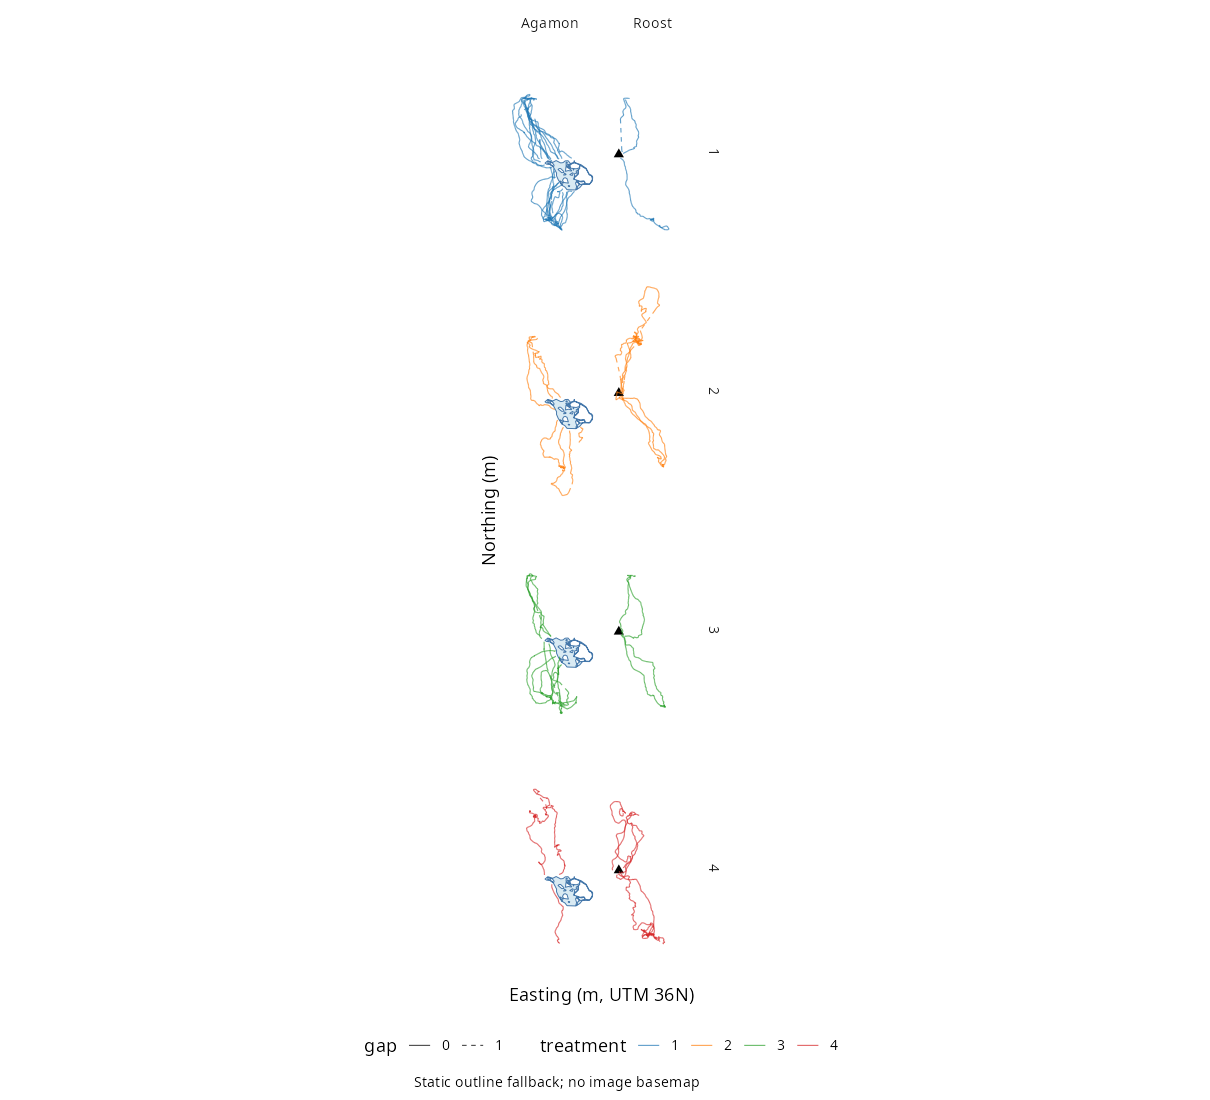

In [14]:
save_figure(p_destination, "rediscretized_destination_panels", 11, 10)


Compact per-panel trajectory plots (one panel per treatment / destination combination).


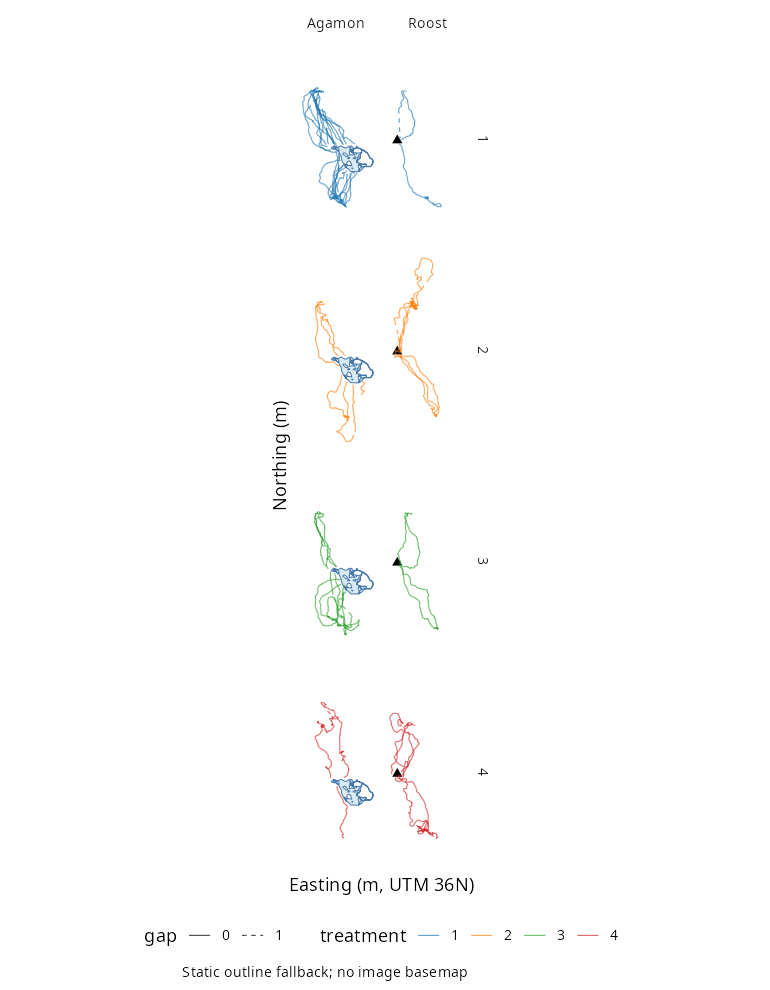

In [15]:
save_figure(p_destination, "rediscretized_destination_panels_compact", 7, 9)


Per-treatment destination panels (compact).


After-localization tracking and destination panels.


Destination flow fields: smoothed-distance and harmonic distance fields over the arena, with the
negative-gradient (goal-approach) direction field that supplies `bearing_to_dest` in the goal-relative
constructions above.


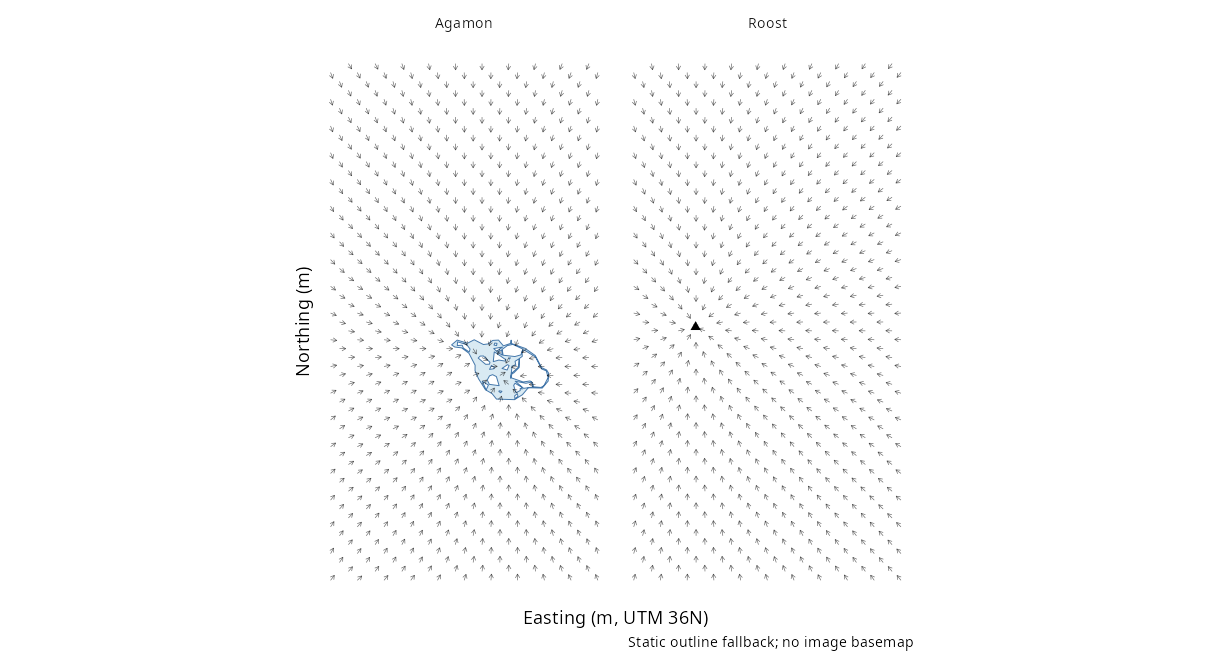

In [16]:
save_figure(p_flow, "destination_flow_fields_smoothed_distance", 11, 6)


### Descriptive circular summaries by treatment

Per-treatment concentration summaries (descriptive, no model): estimated population concentration
($\hat\kappa$), mean resultant length ($\vec{R}$), and the alignment of each individual's mean
bearing to $0^\circ$ (goal direction). These give a first, model-free read on whether treatment
changes directional bias or precision.


In [17]:
theta_grid <- seq(0, 2 * pi, length.out = 361)
kde_vm <- function(y, theta = theta_grid, kappa = 15) {
  vapply(theta, function(t) mean(exp(vm_logpdf(t, y, kappa))), numeric(1))
}
descriptive_data <- track_w_treat[is.finite(track_w_treat$flightAngDiffDest_deg), ]
descriptive_data$HeadingRadians <- wrap(descriptive_data$flightAngDiffDest_deg * pi / 180)
descriptive_data$tag <- factor(descriptive_data$tag, levels = levels(df_track$tag))
descriptive_data$treatment <- factor(descriptive_data$treatment, levels = 1:4)
# Descriptive plots use all finite bearings, as in the source; their input
# need not exclude rows with missing along-field destination distances.
tag_observed <- split(descriptive_data, descriptive_data$tag)
kde_data <- do.call(rbind, lapply(tag_observed, function(g) {
  data.frame(theta = theta_grid, density = kde_vm(g$HeadingRadians),
    tag = as.character(g$tag[1]), treatment = g$treatment[1], destination = g$destination[1])
}))
p_polar_data <- ggplot(kde_data, aes(theta, 1 + density, group = tag, colour = treatment)) +
  geom_path(linewidth = 0.3, alpha = 0.6) +
  scale_x_continuous(limits = c(0, 2 * pi), expand = c(0, 0)) +
  coord_polar() + facet_grid(treatment ~ destination) +
  scale_colour_manual(values = treatment_colors) + labs(x = "goal-relative angle (rad)", y = "1 + density")
estimate_kappa <- function(rbar, n) {
  rbar <- min(max(rbar, 0), 0.999999999)
  if (rbar < 0.53) {
    k <- 2 * rbar + rbar^3 + (5 / 6) * rbar^5
  } else if (rbar < 0.85) {
    k <- -0.4 + 1.39 * rbar + 0.43 / (1 - rbar)
  } else {
    k <- 1 / (rbar^3 - 4 * rbar^2 + 3 * rbar)
  }
  if (n > 1L) {
    if (k < 2) {
      k <- if (k > 0) max(k - 2 / (n * k), 0) else 0
    } else {
      k <- (n - 1)^3 * k / (n^3 + n)
    }
  }
  k
}
descriptive <- do.call(rbind, lapply(tag_observed, function(g) {
  a <- g$HeadingRadians
  rbar <- resultant(a)
  data.frame(tag = as.character(g$tag[1]), treatment = g$treatment[1],
    n = length(a), Rbar = rbar, kappa_hat = estimate_kappa(rbar, length(a)),
    alignment0 = mean(cos(a)))
}))
descriptive_plot <- function(variable, label) {
  s <- do.call(rbind, lapply(split(descriptive, descriptive$treatment), function(g) {
    q <- quantile(g[[variable]], c(0.025, 0.25, 0.5, 0.75, 0.975), names = FALSE)
    data.frame(treatment = g$treatment[1], low = q[1], q25 = q[2], median = q[3], q75 = q[4], high = q[5])
  }))
  ggplot(s, aes(treatment, median, colour = treatment)) +
    geom_linerange(aes(ymin = low, ymax = high), linewidth = 0.4) +
    geom_linerange(aes(ymin = q25, ymax = q75), linewidth = 2) + geom_point(size = 2) +
    scale_colour_manual(values = treatment_colors) +
    scale_x_discrete(labels = treatment_labels) + labs(x = "", y = label) +
    theme(legend.position = "none", axis.text.x = element_text(angle = 20, hjust = 1))
}
p_kappa_desc <- descriptive_plot("kappa_hat", "per-tag kappa estimate")
p_R_desc <- descriptive_plot("Rbar", "per-tag mean resultant length")
p_align_desc <- descriptive_plot("alignment0", "per-tag alignment E[cos(theta)]")


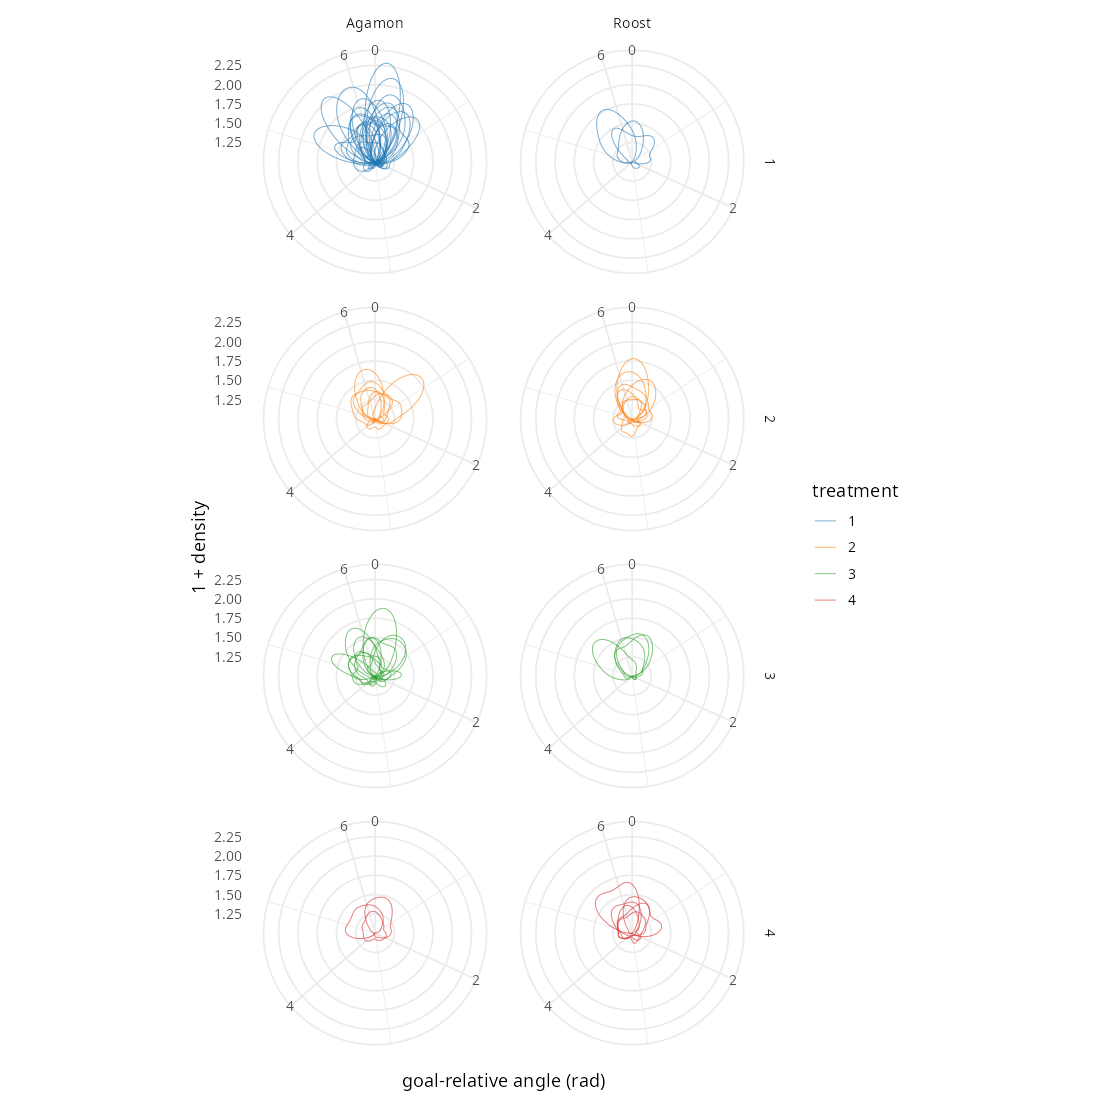

In [18]:
save_figure(p_polar_data, "polar_vonmises_kde_all", 10, 10)


$\hat\kappa$ (concentration) by treatment, median with percentile bands.


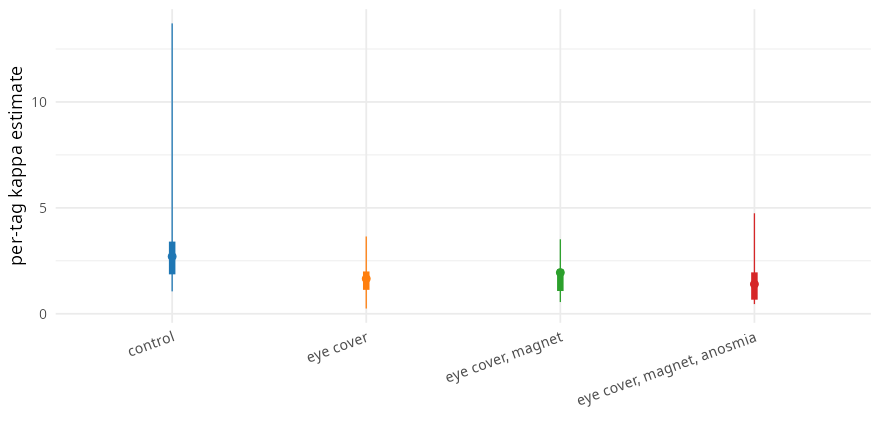

In [19]:
save_figure(p_kappa_desc, "kappa_hat_by_treatment_median_percentiles", 8, 4)


Mean resultant length $\vec{R}$ by treatment, median with percentile bands.


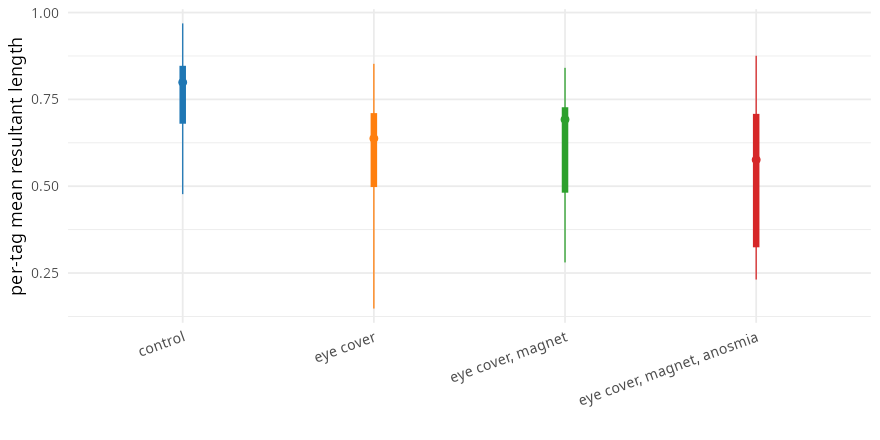

In [20]:
save_figure(p_R_desc, "rbar_by_treatment_median_percentiles", 8, 4)


Alignment of individual mean bearings to $0^\circ$ by treatment, median with percentile bands.


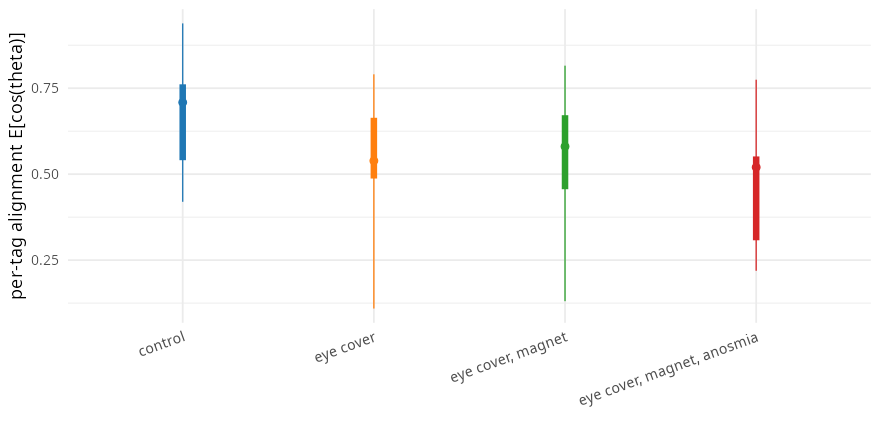

In [21]:
save_figure(p_align_desc, "alignment0_by_treatment_median_percentiles", 8, 4)


## 6. Single von Mises treatment model (baseline)

Build the modeling table for a **single** von Mises likelihood: response `HeadingRadians` (the
goal-relative bearing wrapped to $(-\pi, \pi]$), a **treatment** fixed effect, and a **per-tag random
intercept** (repeated measures). Predictors (`z_log_dist`) are standardized. This is the
non-mixed baseline; the mixture below will be judged against it.



Direction tag shifts are Normal with HalfNormal(1/sqrt(30)) scale; the
concentration intercept prior is Normal(inverse_softplus(3), 1). The
von Mises tag hyperprior belongs to the mixture model below. All
treatment effects use control (1) as reference.


In [22]:
# Python c41 uses Normal tag direction effects with a HalfNormal
# sd = 1/sqrt(30), not a von Mises tag prior. Preserve that actual model.
vector_vm <- stanvar(scode = "
  real unwrap_von_mises_vect_lpdf(vector y, real mu, real kappa) {
    real lp = 0;
    for (i in 1:num_elements(y)) lp += unwrap_von_mises_lpdf(y[i] | mu, kappa);
    return lp;
  }
", block = "functions")
base_form <- bf(HeadingRadians ~ mu,
  nlf(mu ~ beta0 + tagshift),
  beta0 ~ 0 + Intercept + treat2 + treat3 + treat4,
  tagshift ~ 0 + (1 | tag),
  kappa ~ 0 + Intercept + treat2 + treat3 + treat4 + (1 | tag),
  family = unwrap_von_mises)
base_priors <- (
  prior("uniform(-pi(), pi())", class = "b", nlpar = "beta0",
    lb = -3.141592653589793, ub = 3.141592653589793) +
  set_prior("target += unwrap_von_mises_lpdf(b_beta0[1] | 0, 1)", check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_beta0[2:4] | 0, 2)", check = FALSE) +
  prior("normal(0, 0.18257418583505536)", class = "sd", nlpar = "tagshift") +
  prior("normal(log(exp(3) - 1), 1)", class = "b", coef = "Intercept", dpar = "kappa") +
  prior("normal(0, 1)", class = "b", coef = "treat2", dpar = "kappa") +
  prior("normal(0, 1)", class = "b", coef = "treat3", dpar = "kappa") +
  prior("normal(0, 1)", class = "b", coef = "treat4", dpar = "kappa") +
  prior("normal(0, 1)", class = "sd", dpar = "kappa")
)
# EQUIVALENCE NOTE: exact c41 values govern the baseline; the centered
# von Mises coefficient-vector pattern is needed for fixed direction
# effects, while tag shifts remain non-centered Gaussian effects here.
base_stanvars <- stan_unwrap_fun + modulo_circular_fun + vector_vm
base_stan <- make_stancode(base_form, data = df_track, prior = base_priors,
                           stanvars = base_stanvars)
stopifnot(grepl("unwrap_von_mises_vect_lpdf", base_stan, fixed = TRUE),
          grepl("lower=-3.14159", gsub(" ", "", base_stan), fixed = TRUE),
          grepl("upper=3.14159", gsub(" ", "", base_stan), fixed = TRUE))
cat(base_stan)
# Check the generated parameters block and coefficient order before init:
# b_beta0 has four bounded entries: Intercept, treat2, treat3, treat4.
base_standata <- make_standata(base_form, data = df_track, prior = base_priors,
                              stanvars = base_stanvars)
base_parameter_block <- regmatches(base_stan,
  regexpr("(?m)^parameters\\s*\\{[^}]*\\}", base_stan, perl = TRUE))
base_parameter_block <- gsub("[[:space:]]", "", base_parameter_block)
stopifnot(length(base_parameter_block) == 1L,
  grepl(paste0("vector<lower=-3\\.14159[0-9]*,upper=3\\.14159[0-9]*>",
    "\\[K_beta0\\]b_beta0;"), base_parameter_block),
  base_standata$K_beta0 == 4L,
  identical(colnames(base_standata$X_beta0),
    c("Intercept", "treat2", "treat3", "treat4")))

# Bounded angular coefficients can strand chains in distinct 2*pi-equivalent
# wrap classes when heading sums straddle the seam. Seed all chains in one
# class with data-derived anchors and jitter too small to cross a seam.
# Jitter is added AFTER wrapping; initialization changes only the sampler
# path, never the posterior. Initialize only b_beta0 here; Gaussian tagshift
# effects and all kappa parameters retain CmdStan defaults.
base_treat_mean <- tapply(df_track$HeadingRadians, df_track$treatment, circ_mean)
mu_anchor <- as.numeric(base_treat_mean[levels(df_track$treatment)[1]])
treat_anchor <- as.numeric(mod_circular(
  base_treat_mean[levels(df_track$treatment)[-1]] - mu_anchor))
stopifnot(length(base_treat_mean) == nlevels(df_track$treatment),
  length(treat_anchor) == 3L,
  length(c(mu_anchor, treat_anchor)) == base_standata$K_beta0,
  abs(mu_anchor) < pi - 0.2, all(abs(treat_anchor) < pi - 0.5))
mk_init <- function(anchor_seed) {
  set.seed(anchor_seed)
  j <- function(n) runif(n, -0.08, 0.08)
  list(b_beta0 = as.numeric(c(mu_anchor, treat_anchor) + j(base_standata$K_beta0)))
}
set.seed(123)
fit_vm <- brm(base_form, data = df_track, prior = base_priors,
  stanvars = base_stanvars, backend = "cmdstanr",
  chains = CHAINS, iter = ITER, warmup = WARMUP, cores = CHAINS,
  seed = SEED,
  init = lapply(seq_len(CHAINS), function(k) mk_init(SEED + k)),
  control = list(adapt_delta = 0.97))
base_parameters <- posterior::variables(posterior::as_draws_array(fit_vm))
base_angular <- base_parameters[grepl("^b_beta0_", base_parameters)]
base_summary <- diagnose_fit(fit_vm, angular = base_angular)


// generated with brms 2.23.0
functions {
  /* softplus link function inverse to 'log1p_exp'
   * Args:
   *   x: a positive scalar
   * Returns:
   *   a scalar in (-Inf, Inf)
   */
   real log_expm1(real x) {
     return log(expm1(x));
   }
  /* softplus link function inverse to 'log1p_exp' (vectorized)
   * Args:
   *   x: a positive vector
   * Returns:
   *   a vector in (-Inf, Inf)
   */
   vector log_expm1(vector x) {
     return log(expm1(x));
   }
  
  real unwrap_von_mises_lpdf(real y, real mu, real kappa) {
    return von_mises_lpdf(y | modulo_circular(mu), kappa);
  }
  real unwrap_von_mises_rng(real mu, real kappa) {
    return von_mises_rng( modulo_circular(mu) , kappa);
  }

  
  real modulo_circular(real y) {
    return fmod(y + pi(), 2*pi()) - pi();
  }

  
  real unwrap_von_mises_vect_lpdf(vector y, real mu, real kappa) {
    real lp = 0;
    for (i in 1:num_elements(y)) lp += unwrap_von_mises_lpdf(y[i] | mu, kappa);
    return lp;
  }

}
data {
  int<lower=1> N;  // 

Start sampling



Init values were only set for a subset of parameters. 
Missing init values for the following parameters:
 - chain 1: b_kappa, sd_1, z_1, sd_2, z_2
 - chain 2: b_kappa, sd_1, z_1, sd_2, z_2
 - chain 3: b_kappa, sd_1, z_1, sd_2, z_2
 - chain 4: b_kappa, sd_1, z_1, sd_2, z_2

To disable this message use options(cmdstanr_warn_inits = FALSE).




Running MCMC with 4 parallel chains...

Chain 1 Iteration:    1 / 4000 [  0%]  (Warmup) 
Chain 2 Iteration:    1 / 4000 [  0%]  (Warmup) 
Chain 3 Iteration:    1 / 4000 [  0%]  (Warmup) 
Chain 4 Iteration:    1 / 4000 [  0%]  (Warmup) 
Chain 1 Iteration:  100 / 4000 [  2%]  (Warmup) 
Chain 2 Iteration:  100 / 4000 [  2%]  (Warmup) 
Chain 4 Iteration:  100 / 4000 [  2%]  (Warmup) 
Chain 3 Iteration:  100 / 4000 [  2%]  (Warmup) 
Chain 1 Iteration:  200 / 4000 [  5%]  (Warmup) 
Chain 4 Iteration:  200 / 4000 [  5%]  (Warmup) 
Chain 2 Iteration:  200 / 4000 [  5%]  (Warmup) 
Chain 1 Iteration:  300 / 4000 [  7%]  (Warmup) 
Chain 3 Iteration:  200 / 4000 [  5%]  (Warmup) 
Chain 4 Iteration:  300 / 4000 [  7%]  (Warmup) 
Chain 2 Iteration:  300 / 4000 [  7%]  (Warmup) 
Chain 1 Iteration:  400 / 4000 [ 10%]  (Warmup) 
Chain 3 Iteration:  300 / 4000 [  7%]  (Warmup) 
Chain 2 Iteration:  400 / 4000 [ 10%]  (Warmup) 
Chain 4 Iteration:  400 / 4000 [ 10%]  (Warmup) 
Chain 3 Iteration:  400 / 400

Loading required namespace: rstan



Divergences: not retained in this fit object (see R-hat/ESS below).
                          parameter         mean         sd      rhat ess_bulk
1                 b_beta0_Intercept -0.073117219 0.08153771 1.0002833 1015.740
2                    b_beta0_treat2  0.154058757 0.15071390 1.0015558 1277.125
3                    b_beta0_treat3 -0.141934229 0.14453922 0.9999711 1171.832
4                    b_beta0_treat4 -0.068370820 0.17242886 1.0005634 1832.228
5                 b_kappa_Intercept  2.614732048 0.25458797 1.0001382 1469.008
6                    b_kappa_treat2 -1.206993281 0.41276433 0.9999367 1588.321
7                    b_kappa_treat3 -0.958484498 0.41302327 0.9999659 1577.257
8                    b_kappa_treat4 -1.152462226 0.48031774 0.9999836 1794.483
9           sd_tag__kappa_Intercept  1.387948155 0.15673338 0.9998951 2021.807
10       sd_tag__tagshift_Intercept  0.445171998 0.03930475 1.0009139 1845.840
11     r_tag__kappa[7535,Intercept] -1.757918377 0.54318871 1.0

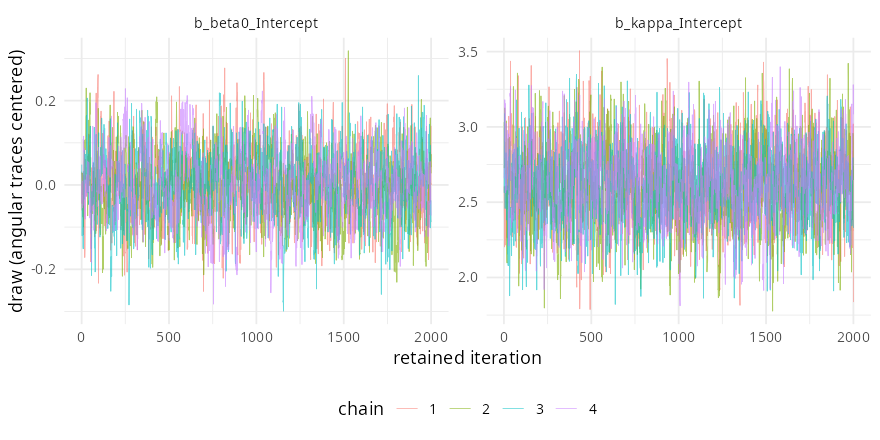

In [23]:
save_figure(trace_plot(fit_vm, c("b_beta0_Intercept", "b_kappa_Intercept"), base_angular), "vonmises_trace", 8, 4)


### PSIS-LOO comparison (vMU vs vM)

Out-of-sample comparison of the two fits by PSIS-LOO. The logit-scale posterior of the mixture weight is mapped back to $(0, 1)$, so the directed-component probability $p$ is reported in interpretable terms.


In [24]:
qs <- c(0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99)
data.frame(quantile = qs, probability = plogis(qnorm(qs, qlogis(0.9), 1)))


quantile,probability
<dbl>,<dbl>
0.01,0.4677640
0.05,0.6346855
0.10,0.7141596
0.25,0.8209408
0.50,0.9000000
0.75,0.9464303
0.90,0.9700778
0.95,0.9790014
0.99,0.9892663


### Fit the full von Mises--Uniform mixture

`mix_form` specifies **each step** as
$\text{Heading} \sim p\,\mathrm{VM}(\mu, \kappa) + (1-p)\,\mathrm{Uniform}$, with

- $\mu$ = goal-directed mean direction (population `mu0` + per-tag von Mises offsets + treatment
  offsets),
- $\kappa$ = goal-directed concentration (softplus-linked, per-tag offsets + treatment offsets),
- $p$ = probability a step is goal-directed (logit-linked, per-tag offsets + treatment offset).

The undirected (uniform) component explicitly represents exploratory movement, so a single
concentration no longer has to absorb both dispersion during homing and wandering — and no
post-treatment "homing" filter is needed.



In [25]:
# Cell 53's exact uniform-circle component; no near-uniform approximation
# enters the likelihood. brms generates target += unwrap_vmu_lpdf(...).
unwrap_vmu <- custom_family("unwrap_vmu", dpars = c("mu", "kappa", "pgoal"),
  links = c("identity", "softplus", "logit"),
  lb = c(NA, 0, 0), ub = c(NA, NA, 1), type = "real")
mixture_functions <- stanvar(scode = "
  real unwrap_vmu_lpdf(real y, real mu, real kappa, real pgoal) {
    return log_mix(pgoal, unwrap_von_mises_lpdf(y | mu, kappa), -log(2*pi()));
  }
  real unwrap_vmu_rng(real mu, real kappa, real pgoal) {
    if (bernoulli_rng(pgoal)) return unwrap_von_mises_rng(mu, kappa);
    return uniform_rng(-pi(), pi());
  }
", block = "functions")
mixture_hyper <- stanvar(scode = "real<lower=0> kmu_tag;", block = "parameters")
for (t in 2:4) df_track[[paste0("treat", t)]] <- as.integer(df_track$treatment == as.character(t))
mix_form <- bf(HeadingRadians ~ mu,
  nlf(mu ~ mu0 + mutreat + mutag),
  mu0 ~ 1,
  mutreat ~ 0 + treat2 + treat3 + treat4,
  mutag ~ 0 + tag,
  kappa ~ 0 + Intercept + treat2 + treat3 + treat4 + (1 | tag),
  pgoal ~ 0 + Intercept + treat2 + treat3 + treat4 + (1 | tag),
  family = unwrap_vmu)
mix_priors <- (
  prior("uniform(-pi(), pi())", class = "b", nlpar = "mu0",
    lb = -3.141592653589793, ub = 3.141592653589793) +
  prior("uniform(-pi(), pi())", class = "b", nlpar = "mutreat",
    lb = -3.141592653589793, ub = 3.141592653589793) +
  prior("uniform(-pi(), pi())", class = "b", nlpar = "mutag",
    lb = -3.141592653589793, ub = 3.141592653589793) +
  set_prior("target += unwrap_von_mises_lpdf(b_mu0[1] | 0, 1)", check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_mutreat | 0, 2)", check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_mutag | 0, kmu_tag)", check = FALSE) +
  set_prior("target += lognormal_lpdf(kmu_tag | log(30), 0.1)", check = FALSE) +
  prior("normal(log(exp(5) - 1), 1)", class = "b", coef = "Intercept", dpar = "kappa") +
  prior("normal(0, 1)", class = "b", coef = "treat2", dpar = "kappa") +
  prior("normal(0, 1)", class = "b", coef = "treat3", dpar = "kappa") +
  prior("normal(0, 1)", class = "b", coef = "treat4", dpar = "kappa") +
  prior("normal(0, 1)", class = "sd", dpar = "kappa") +
  prior("normal(log(0.8 / 0.2), 1)", class = "b", coef = "Intercept", dpar = "pgoal") +
  prior("normal(0, 1)", class = "b", coef = "treat2", dpar = "pgoal") +
  prior("normal(0, 1)", class = "b", coef = "treat3", dpar = "pgoal") +
  prior("normal(0, 1)", class = "b", coef = "treat4", dpar = "pgoal") +
  prior("normal(0, 1)", class = "sd", dpar = "pgoal")
)
# Uniform factors add constants only. Explicit von Mises targets avoid
# nonexistent custom-prior CDFs when brms normalizes bounded priors.
# PyMC's sigmoid([eta,-eta]) is (plogis(eta),1-plogis(eta)), not a
# two-logit softmax. The pgoal formula therefore uses eta, not 2*eta.
mix_stanvars <- base_stanvars + mixture_functions + mixture_hyper
mix_stan <- make_stancode(mix_form, data = df_track, prior = mix_priors,
                          stanvars = mix_stanvars)
stopifnot(grepl("log_mix(pgoal", mix_stan, fixed = TRUE),
          grepl("kmu_tag", mix_stan, fixed = TRUE),
          grepl("target += unwrap_vmu_lpdf", mix_stan, fixed = TRUE))
cat(mix_stan)
# Check the generated parameters block and coefficient order before init:
# b_mu0: Intercept (1); b_mutreat: treat2, treat3, treat4 (3);
# b_mutag: one entry per tag, in levels(df_track$tag) order.
mix_standata <- make_standata(mix_form, data = df_track, prior = mix_priors,
                             stanvars = mix_stanvars)
mix_parameter_block <- regmatches(mix_stan,
  regexpr("(?m)^parameters\\s*\\{[^}]*\\}", mix_stan, perl = TRUE))
mix_parameter_block <- gsub("[[:space:]]", "", mix_parameter_block)
stopifnot(length(mix_parameter_block) == 1L,
  all(vapply(c("mu0", "mutreat", "mutag"), function(p) {
    grepl(paste0("vector<lower=-3\\.14159[0-9]*,upper=3\\.14159[0-9]*>",
      "\\[K_", p, "\\]b_", p, ";"), mix_parameter_block)
  }, logical(1))),
  grepl("real<lower=0>kmu_tag;", mix_parameter_block, fixed = TRUE),
  mix_standata$K_mu0 == 1L, mix_standata$K_mutreat == 3L,
  mix_standata$K_mutag == nlevels(df_track$tag),
  identical(colnames(mix_standata$X_mu0), "Intercept"),
  identical(colnames(mix_standata$X_mutreat), c("treat2", "treat3", "treat4")),
  isTRUE(all.equal(mix_standata$X_mutag,
    model.matrix(~ 0 + tag, data = df_track), check.attributes = FALSE)))

# Bounded angular coefficients can strand chains in distinct 2*pi-equivalent
# wrap classes when heading sums straddle the seam. Seed all chains in one
# class with data-derived anchors and jitter too small to cross a seam.
# Jitter is added AFTER wrapping; initialization changes only the sampler
# path, never the posterior. Initialize b_mu0, b_mutreat, b_mutag, and kmu_tag
# (30, the middle of its LogNormal(log(30), 0.1) hyperprior). Gaussian random
# effects and all kappa/pgoal parameters retain CmdStan defaults.
mix_treat_mean <- tapply(df_track$HeadingRadians, df_track$treatment, circ_mean)
mu0_anchor <- as.numeric(mix_treat_mean[levels(df_track$treatment)[1]])
mutreat_anchor <- as.numeric(mod_circular(
  mix_treat_mean[levels(df_track$treatment)[-1]] - mu0_anchor))
tag_mean <- tapply(df_track$HeadingRadians, df_track$tag, circ_mean)
tag_treatment <- vapply(levels(df_track$tag), function(tag_id) {
  treatment <- unique(as.character(df_track$treatment[df_track$tag == tag_id]))
  stopifnot(length(treatment) == 1L)
  treatment
}, character(1))
mutag_anchor <- as.numeric(mod_circular(tag_mean[levels(df_track$tag)] -
  mu0_anchor - c(0, mutreat_anchor)[match(tag_treatment, levels(df_track$treatment))]))
stopifnot(length(mix_treat_mean) == nlevels(df_track$treatment),
  length(mu0_anchor) == mix_standata$K_mu0,
  length(mutreat_anchor) == mix_standata$K_mutreat,
  length(tag_mean) == nlevels(df_track$tag),
  length(mutag_anchor) == mix_standata$K_mutag,
  abs(mu0_anchor) < pi - 0.2,
  all(abs(mutreat_anchor) < pi - 0.5), all(abs(mutag_anchor) < pi - 0.5))
mk_init <- function(anchor_seed) {
  set.seed(anchor_seed)
  j <- function(n) runif(n, -0.08, 0.08)
  list(b_mu0 = as.numeric(mu0_anchor + j(1)),
    b_mutreat = as.numeric(mutreat_anchor + j(length(mutreat_anchor))),
    b_mutag = as.numeric(mutag_anchor + j(length(mutag_anchor))),
    kmu_tag = 30)
}
set.seed(123)
fit_mix <- brm(mix_form, data = df_track, prior = mix_priors,
  stanvars = mix_stanvars, backend = "cmdstanr",
  chains = CHAINS, iter = ITER, warmup = WARMUP, cores = CHAINS,
  seed = SEED,
  init = lapply(seq_len(CHAINS), function(k) mk_init(SEED + k)),
  control = list(adapt_delta = 0.97))
mix_parameters <- posterior::variables(posterior::as_draws_array(fit_mix))
mix_angular <- mix_parameters[grepl("^b_(mu0|mutreat|mutag)_", mix_parameters)]
mix_summary <- diagnose_fit(fit_mix, angular = mix_angular)


// generated with brms 2.23.0
functions {
  /* softplus link function inverse to 'log1p_exp'
   * Args:
   *   x: a positive scalar
   * Returns:
   *   a scalar in (-Inf, Inf)
   */
   real log_expm1(real x) {
     return log(expm1(x));
   }
  /* softplus link function inverse to 'log1p_exp' (vectorized)
   * Args:
   *   x: a positive vector
   * Returns:
   *   a vector in (-Inf, Inf)
   */
   vector log_expm1(vector x) {
     return log(expm1(x));
   }
  
  real unwrap_von_mises_lpdf(real y, real mu, real kappa) {
    return von_mises_lpdf(y | modulo_circular(mu), kappa);
  }
  real unwrap_von_mises_rng(real mu, real kappa) {
    return von_mises_rng( modulo_circular(mu) , kappa);
  }

  
  real modulo_circular(real y) {
    return fmod(y + pi(), 2*pi()) - pi();
  }

  
  real unwrap_von_mises_vect_lpdf(vector y, real mu, real kappa) {
    real lp = 0;
    for (i in 1:num_elements(y)) lp += unwrap_von_mises_lpdf(y[i] | mu, kappa);
    return lp;
  }

  
  real unwrap_vmu_lpdf(real 

Start sampling



Init values were only set for a subset of parameters. 
Missing init values for the following parameters:
 - chain 1: b_kappa, b_pgoal, sd_1, z_1, sd_2, z_2
 - chain 2: b_kappa, b_pgoal, sd_1, z_1, sd_2, z_2
 - chain 3: b_kappa, b_pgoal, sd_1, z_1, sd_2, z_2
 - chain 4: b_kappa, b_pgoal, sd_1, z_1, sd_2, z_2

To disable this message use options(cmdstanr_warn_inits = FALSE).




Running MCMC with 4 parallel chains...

Chain 1 Iteration:    1 / 4000 [  0%]  (Warmup) 
Chain 2 Iteration:    1 / 4000 [  0%]  (Warmup) 
Chain 3 Iteration:    1 / 4000 [  0%]  (Warmup) 
Chain 4 Iteration:    1 / 4000 [  0%]  (Warmup) 
Chain 3 Iteration:  100 / 4000 [  2%]  (Warmup) 
Chain 2 Iteration:  100 / 4000 [  2%]  (Warmup) 
Chain 1 Iteration:  100 / 4000 [  2%]  (Warmup) 
Chain 4 Iteration:  100 / 4000 [  2%]  (Warmup) 
Chain 3 Iteration:  200 / 4000 [  5%]  (Warmup) 
Chain 2 Iteration:  200 / 4000 [  5%]  (Warmup) 
Chain 3 Iteration:  300 / 4000 [  7%]  (Warmup) 
Chain 1 Iteration:  200 / 4000 [  5%]  (Warmup) 
Chain 2 Iteration:  300 / 4000 [  7%]  (Warmup) 
Chain 4 Iteration:  200 / 4000 [  5%]  (Warmup) 
Chain 3 Iteration:  400 / 4000 [ 10%]  (Warmup) 
Chain 1 Iteration:  300 / 4000 [  7%]  (Warmup) 
Chain 2 Iteration:  400 / 4000 [ 10%]  (Warmup) 
Chain 4 Iteration:  300 / 4000 [  7%]  (Warmup) 
Chain 3 Iteration:  500 / 4000 [ 12%]  (Warmup) 
Chain 1 Iteration:  400 / 400

Divergences: not retained in this fit object (see R-hat/ESS below).
                       parameter         mean         sd      rhat  ess_bulk
1                b_mu0_Intercept -0.080915607 0.05054079 1.0009213  896.9981
2               b_mutreat_treat2  0.155135862 0.09200063 1.0003060 1443.9283
3               b_mutreat_treat3 -0.166683211 0.08667506 1.0022980 1235.7964
4               b_mutreat_treat4 -0.057018444 0.10696044 1.0028967 1784.0035
5                b_mutag_tag7535 -0.889737353 0.11553147 1.0022163 3284.2345
6                b_mutag_tag7537  0.013879594 0.11218929 0.9999929 4636.9735
7                b_mutag_tag7538 -0.496214761 0.10727212 0.9999095 3337.5495
8                b_mutag_tag7539 -0.156103290 0.10312408 1.0001621 3522.1612
9                b_mutag_tag7541 -0.070870907 0.09102705 0.9999302 2725.5401
10               b_mutag_tag7542 -0.505393707 0.13948977 1.0009027 5868.4058
11               b_mutag_tag7544  0.096429203 0.10746476 1.0010306 3178.4743
12      

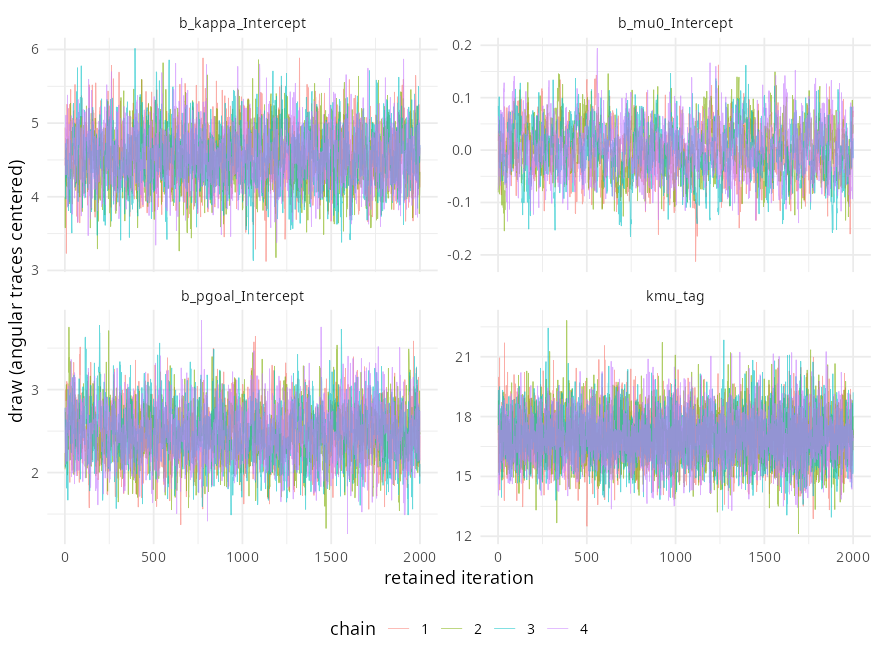

In [26]:
save_figure(trace_plot(fit_mix, c("b_mu0_Intercept", "b_kappa_Intercept", "b_pgoal_Intercept", "kmu_tag"), mix_angular), "mixture_trace", 8, 6)


Sampling summary for the vMU fit (check ESS / $\hat{R}$ before interpreting).


In [27]:
response_parameters <- function(fit, newdata, mixture = FALSE,
                                population = FALSE, draw_ids = NULL) {
  # brms returns [draws x grid]; transpose explicitly to [grid x draws].
  get_lp <- function(dpar = NULL, nlpar = NULL, transform = FALSE) {
    t(posterior_linpred(fit, newdata = newdata, dpar = dpar, nlpar = nlpar,
      transform = transform, re_formula = if (population) NA else NULL,
      draw_ids = draw_ids))
  }
  if (population) {
    # Circular tag vectors are nonlinear population coefficients, so a
    # re_formula alone cannot exclude them. Evaluate the relevant nlpars.
    mu <- if (mixture) get_lp(nlpar = "mu0") + get_lp(nlpar = "mutreat") else get_lp(nlpar = "beta0")
  } else {
    mu <- get_lp(dpar = "mu")
  }
  kappa <- get_lp(dpar = "kappa", transform = TRUE)
  p <- if (mixture) get_lp(dpar = "pgoal", transform = TRUE) else matrix(1, nrow(mu), ncol(mu))
  stopifnot(nrow(mu) == nrow(newdata), identical(dim(mu), dim(kappa)),
            identical(dim(mu), dim(p)), all(kappa > 0), all(p >= 0 & p <= 1))
  list(mu = wrap(mu), kappa = kappa, p = p)
}
population_grid <- data.frame(treatment = factor(1:4, levels = 1:4),
                              tag = factor(levels(df_track$tag)[1], levels = levels(df_track$tag)))
for (t in 2:4) population_grid[[paste0("treat", t)]] <- as.integer(population_grid$treatment == as.character(t))
set.seed(123)
PLOT_DRAWS <- if (quick_run) 200L else 2000L
plot_vm_ids <- sample.int(posterior::ndraws(posterior::as_draws_array(fit_vm)), PLOT_DRAWS)
plot_mix_ids <- sample.int(posterior::ndraws(posterior::as_draws_array(fit_mix)), PLOT_DRAWS)
pop_vm <- response_parameters(fit_vm, population_grid, population = TRUE, draw_ids = plot_vm_ids)
pop_mix <- response_parameters(fit_mix, population_grid, mixture = TRUE,
  population = TRUE, draw_ids = plot_mix_ids)
tag_grid <- df_track[!duplicated(df_track$tag), c("tag", "treatment", "treat2", "treat3", "treat4")]
tag_grid <- tag_grid[order(tag_grid$tag), ]
tag_mix <- response_parameters(fit_mix, tag_grid, mixture = TRUE, draw_ids = plot_mix_ids)


In [28]:
explicit_loo <- function(fit, mixture = FALSE) {
  d <- posterior::as_draws_df(fit)
  ll <- matrix(0, nrow = nrow(d), ncol = nrow(df_track))
  for (start in seq.int(1L, nrow(df_track), by = 128L)) {
    ii <- seq.int(start, min(start + 127L, nrow(df_track)))
    block <- df_track[ii, , drop = FALSE]
    par <- response_parameters(fit, block, mixture = mixture)
    y <- matrix(rep(block$HeadingRadians, ncol(par$mu)), nrow = length(ii))
    log_goal <- vm_logpdf(y, par$mu, par$kappa)
    if (mixture) {
      a <- log(par$p) + log_goal
      b <- log1p(-par$p) - log(2 * pi)
      maximum <- pmax(a, b)
      log_density <- maximum + log(exp(a - maximum) + exp(b - maximum))
    } else {
      log_density <- log_goal
    }
    ll[, ii] <- t(log_density)
  }
  # Scale each likelihood column before exponentiating; relative_eff is
  # invariant to this scaling. Preserve chain IDs rather than flattening.
  likelihood <- exp(sweep(ll, 2, apply(ll, 2, max), "-"))
  r_eff <- loo::relative_eff(likelihood, chain_id = d[[".chain"]])
  loo::loo(ll, r_eff = r_eff)
}
loo_vm <- explicit_loo(fit_vm)
loo_mix <- explicit_loo(fit_mix, mixture = TRUE)
loo_objects <- list("von Mises" = loo_vm, "von Mises-Uniform" = loo_mix)
res_total <- do.call(rbind, lapply(names(loo_objects), function(name) {
  x <- loo_objects[[name]]
  data.frame(model = name, elpd = x$estimates["elpd_loo", "Estimate"],
    se_elpd = x$estimates["elpd_loo", "SE"], pareto_k_max = max(x$diagnostics$pareto_k),
    pareto_n_gt_0.7 = sum(x$diagnostics$pareto_k > 0.7))
}))
res_total <- res_total[order(res_total$elpd, decreasing = TRUE), ]
print(res_total)
pointwise_delta <- loo_mix$pointwise[, "elpd_loo"] - loo_vm$pointwise[, "elpd_loo"]
delta_row <- function(ii, label) {
  delta <- pointwise_delta[ii]
  data.frame(label = label, n = length(ii), delta_elpd = sum(delta),
    se_delta_elpd = if (length(ii) > 1L) sqrt(length(ii) * var(delta)) else NA_real_)
}
delta_df <- rbind(delta_row(seq_len(nrow(df_track)), "Total"),
  do.call(rbind, lapply(levels(df_track$treatment), function(t) {
    delta_row(which(df_track$treatment == t), treatment_labels[[t]])
  })))
print(delta_df)
delta_individual <- do.call(rbind, lapply(split(seq_len(nrow(df_track)), df_track$tag), function(ii) {
  data.frame(tag = as.character(df_track$tag[ii[1]]), treatment = df_track$treatment[ii[1]],
    delta_row(ii, as.character(df_track$tag[ii[1]])))
}))
p_total <- ggplot(res_total, aes(elpd, reorder(model, elpd))) +
  geom_errorbar(aes(xmin = elpd - se_elpd, xmax = elpd + se_elpd), orientation = "y", width = 0.2) +
  geom_point() + labs(x = "PSIS-LOO ELPD +/-1 SE", y = "")
delta_df$label <- factor(delta_df$label, levels = rev(delta_df$label))
p_delta <- ggplot(delta_df, aes(delta_elpd, label)) +
  geom_errorbar(aes(xmin = delta_elpd - se_delta_elpd, xmax = delta_elpd + se_delta_elpd),
                 orientation = "y", width = 0.2) +
  geom_point() + geom_vline(xintercept = 0, linetype = "dashed") +
  labs(x = "delta ELPD (vMU - vM), paired +/-1 SE", y = "")
p_delta_individual <- ggplot(delta_individual,
  aes(delta_elpd, reorder(tag, delta_elpd), colour = treatment)) +
  geom_errorbar(aes(xmin = delta_elpd - se_delta_elpd, xmax = delta_elpd + se_delta_elpd),
    orientation = "y", width = 0.2, linewidth = 0.25) +
  geom_point(size = 1) + facet_wrap(~ treatment, scales = "free_y") +
  geom_vline(xintercept = 0, linetype = "dashed") +
  scale_colour_manual(values = treatment_colors) + labs(x = "delta ELPD per animal", y = "tag")


              model      elpd  se_elpd pareto_k_max pareto_n_gt_0.7
2 von Mises-Uniform -6710.570 60.25002    0.3879183               0
1         von Mises -6829.057 59.32127    0.5036805               0


                       label    n delta_elpd se_delta_elpd
1                      Total 4942 118.487775     17.143848
2                    control 1511  66.850302     12.792188
3                  eye cover 1199  19.328598      7.019283
4          eye cover, magnet 1162  33.698948      8.468420
5 eye cover, magnet, anosmia 1070  -1.390073      2.835252


In [29]:
KAPPA_UNIFORM <- 1e-6
# Preserve the source post-hoc helpers' near-uniform proxy in display/PPC
# summaries. The fitted mixture likelihood and responsibilities use the
# exact uniform-circle density, as in Python c53 and the responsibility helper.
mass_vm <- function(mu, kappa, half_width = pi / 4, grid_n = 721L) {
  theta <- seq(-half_width, half_width, length.out = grid_n)
  weights <- c(0.5, rep(1, grid_n - 2L), 0.5) * diff(theta)[1]
  value <- numeric(length(mu))
  for (j in seq_along(theta)) value <- value + weights[j] * exp(vm_logpdf(theta[j], mu, kappa))
  value
}
parameter_summary <- function(par, grid) {
  do.call(rbind, lapply(seq_len(nrow(grid)), function(j) {
    mu <- par$mu[j, ]
    k <- par$kappa[j, ]
    p <- par$p[j, ]
    f_dir <- exp(vm_logpdf(0, mu, k))
    f_unif <- exp(vm_logpdf(0, 0, KAPPA_UNIFORM))
    values <- list(mu = mu, p = p, kappa = k, mrl = A1_safe(k),
      dens0_dir = f_dir, dens0_mix = p * f_dir + (1 - p) * f_unif,
      mass45 = p * mass_vm(mu, k) + (1 - p) * 0.25,
      align0 = p * A1_safe(k) * cos(mu) + (1 - p) * A1_safe(KAPPA_UNIFORM))
    do.call(rbind, lapply(names(values), function(q) {
      data.frame(grid[j, , drop = FALSE], quantity = q,
        as.list(interval(values[[q]], angular = q == "mu")))
    }))
  }))
}
pop_summary <- parameter_summary(pop_mix, population_grid)
tag_summary <- parameter_summary(tag_mix, tag_grid)
vm_summary <- parameter_summary(pop_vm, population_grid)
mean_hdi_plot <- function(table, quantity, label, reference = NULL) {
  x <- table[table$quantity == quantity, ]
  p <- ggplot(x, aes(mean, treatment, colour = treatment)) +
    geom_errorbar(aes(xmin = low, xmax = high), orientation = "y", width = 0.15) +
    geom_point() + scale_colour_manual(values = treatment_colors) +
    scale_y_discrete(limits = rev(levels(df_track$treatment)), labels = treatment_labels) +
    labs(x = label, y = "") +
    theme(legend.position = "none")
  if (!is.null(reference)) p <- p + geom_vline(xintercept = reference, linetype = "dashed")
  p
}
tag_hdi_plot <- function(quantity, label, reference = NULL) {
  x <- tag_summary[tag_summary$quantity == quantity, ]
  p <- ggplot(x, aes(mean, reorder(tag, mean), colour = treatment)) +
    geom_errorbar(aes(xmin = low, xmax = high), orientation = "y", width = 0.2, linewidth = 0.25) +
    geom_point(size = 1) + facet_wrap(~ treatment, scales = "free_y") +
    scale_colour_manual(values = treatment_colors) + labs(x = label, y = "tag") +
    theme(legend.position = "none")
  population <- pop_summary[pop_summary$quantity == quantity, ]
  p <- p + geom_rect(data = population,
    aes(xmin = low, xmax = high, ymin = -Inf, ymax = Inf),
    inherit.aes = FALSE, fill = "grey50", alpha = 0.12) +
    geom_vline(data = population, aes(xintercept = mean), linewidth = 0.3)
  if (!is.null(reference)) p <- p + geom_vline(xintercept = reference, linetype = "dashed")
  p
}
# Baseline coefficient panels: actual intercept/contrasts, not conditional
# response parameters. Angular intervals are centered on their circular mean.
base_draws <- as.data.frame(posterior::as_draws_df(fit_vm))
base_coef_names <- c("b_beta0_Intercept", paste0("b_beta0_treat", 2:4),
                      "b_kappa_Intercept", paste0("b_kappa_treat", 2:4))
base_coef <- do.call(rbind, lapply(base_coef_names, function(name) {
  angular <- grepl("b_beta0", name, fixed = TRUE)
  data.frame(parameter = name, component = if (angular) "mu (rad)" else "kappa (pre-softplus)",
    as.list(interval(base_draws[[name]], angular = angular)))
}))
p_base_coef <- ggplot(base_coef, aes(mean, parameter)) +
  geom_errorbar(aes(xmin = low, xmax = high), orientation = "y", width = 0.2) +
  geom_point() + geom_vline(xintercept = 0, linetype = "dashed") +
  facet_wrap(~ component, scales = "free") + labs(x = "posterior mean and 95% HDI", y = "")
p_base_density <- mean_hdi_plot(vm_summary, "dens0_dir", "vM density at goal (per radian)", 1 / (2 * pi))

theta <- seq(0, 2 * pi, length.out = 361)
polar_pdf <- do.call(rbind, lapply(seq_len(nrow(population_grid)), function(j) {
  do.call(rbind, lapply(theta, function(t) {
    pdf <- pop_mix$p[j, ] * exp(vm_logpdf(t, pop_mix$mu[j, ], pop_mix$kappa[j, ])) +
      (1 - pop_mix$p[j, ]) * exp(vm_logpdf(t, 0, KAPPA_UNIFORM))
    data.frame(treatment = population_grid$treatment[j], theta = t,
      median = median(pdf), as.list(hdi(pdf)))
  }))
}))
p_mixture_polar <- ggplot(polar_pdf, aes(theta, median, colour = treatment, group = treatment)) +
  geom_ribbon(aes(ymin = low, ymax = high, fill = treatment), alpha = 0.2, colour = NA) +
  geom_path(linewidth = 0.5) + facet_wrap(~ treatment) +
  scale_x_continuous(limits = c(0, 2 * pi), expand = c(0, 0)) + coord_polar() +
  scale_colour_manual(values = treatment_colors) + scale_fill_manual(values = treatment_colors) +
  labs(x = "goal-relative bearing (rad)", y = "mixture density") + theme(legend.position = "none")
p_weight <- mean_hdi_plot(pop_summary, "p", "Mixture weight", 0.5)
p_kappa <- mean_hdi_plot(pop_summary, "kappa", "Directed concentration kappa")
p_mix_density <- mean_hdi_plot(pop_summary, "dens0_mix", "Mixture density at goal", 1 / (2 * pi))
p_dir_density <- mean_hdi_plot(pop_summary, "dens0_dir", "Directed-component density at goal", 1 / (2 * pi))
p_mass <- mean_hdi_plot(pop_summary, "mass45", "Mixture mass within 45 degrees of goal", 0.25)
p_align <- mean_hdi_plot(pop_summary, "align0", "Mixture alignment E[cos(theta)]")
p_mu <- mean_hdi_plot(pop_summary, "mu", "Directed mean angle (rad)")
p_mrl <- mean_hdi_plot(pop_summary, "mrl", "Directed mean resultant length")
dens_xlim <- c(0, 1.05 * max(pop_summary$high[pop_summary$quantity == "dens0_dir"],
  vm_summary$high[vm_summary$quantity == "dens0_dir"]))


Treatment coefficients for the mu and kappa submodels (vM baseline).


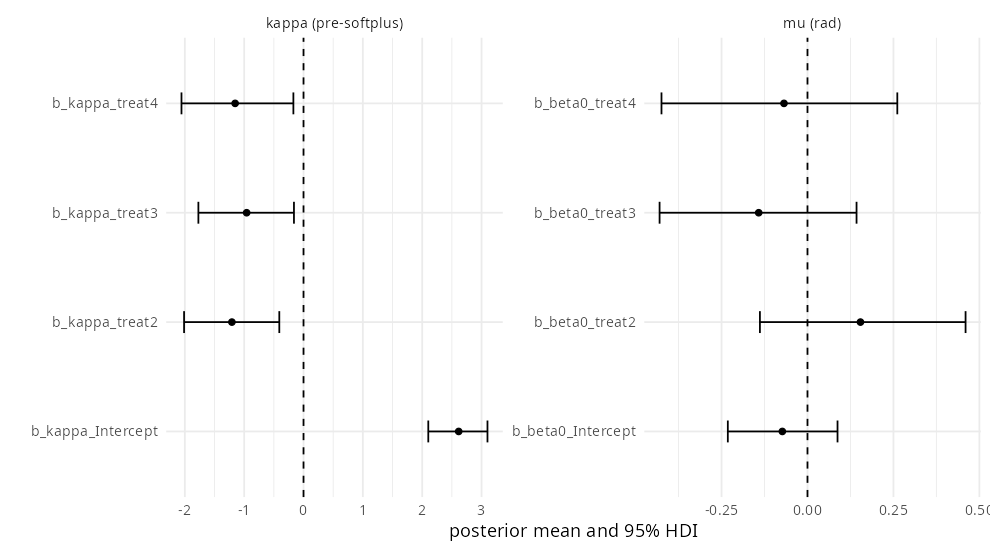

In [30]:
save_figure(p_base_coef, "treatment_coefficients_mu_kappa", 9, 5)


Posterior predictive density at the goal direction ($0^\circ$, i.e. straight toward the goal) by
treatment for the vM baseline.


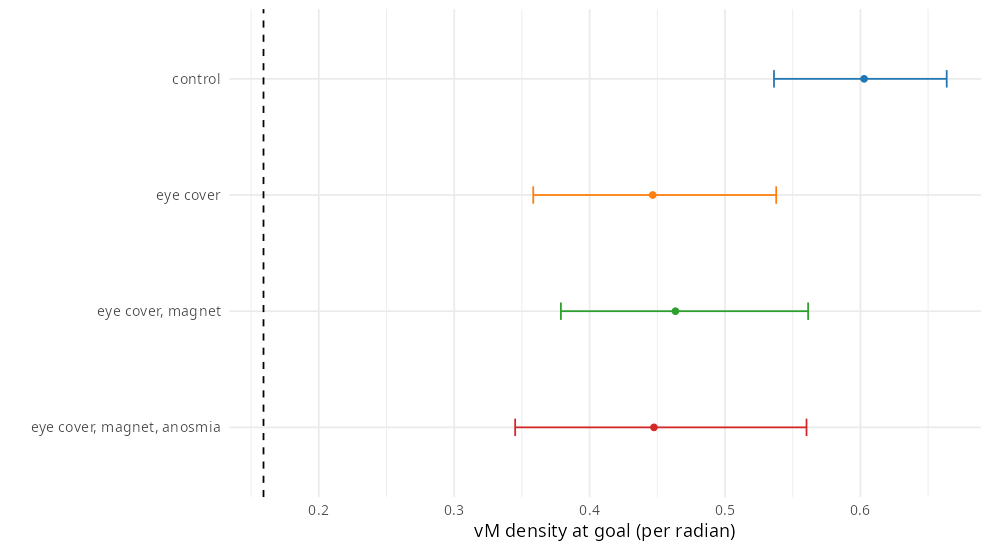

In [31]:
save_figure(p_base_density, "treatment_pred_density_at0_mu_kappa", 9, 5)


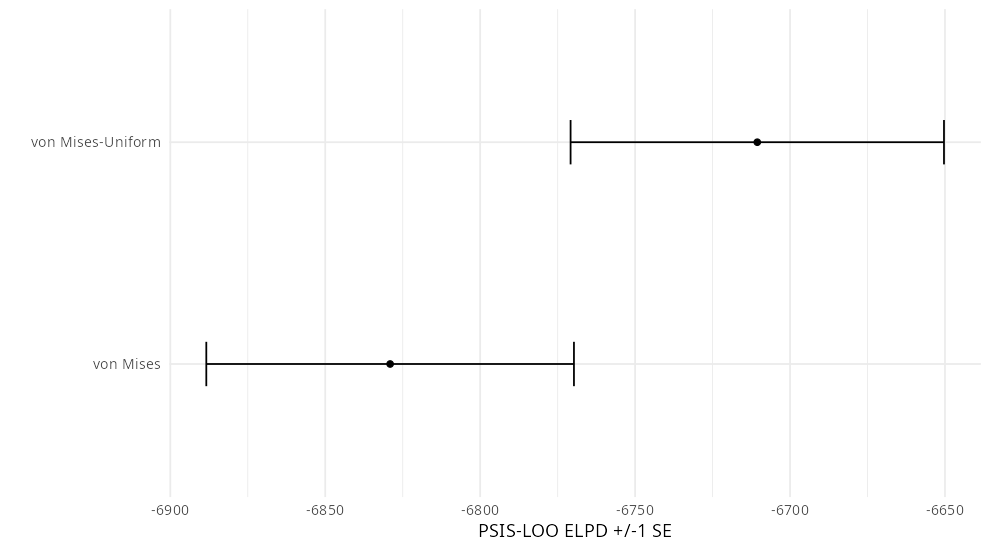

In [32]:
save_figure(p_total, "psisloo_total_elpd_all_models", 9, 5)


Compute **$\Delta$ELPD = vMU $-$ vM** with PSIS-LOO, total and stratified by treatment, with the SE of
the total. A positive value means the mixture predicts goal-relative headings better out of sample;
it is the evidence for a non-trivial undirected component.


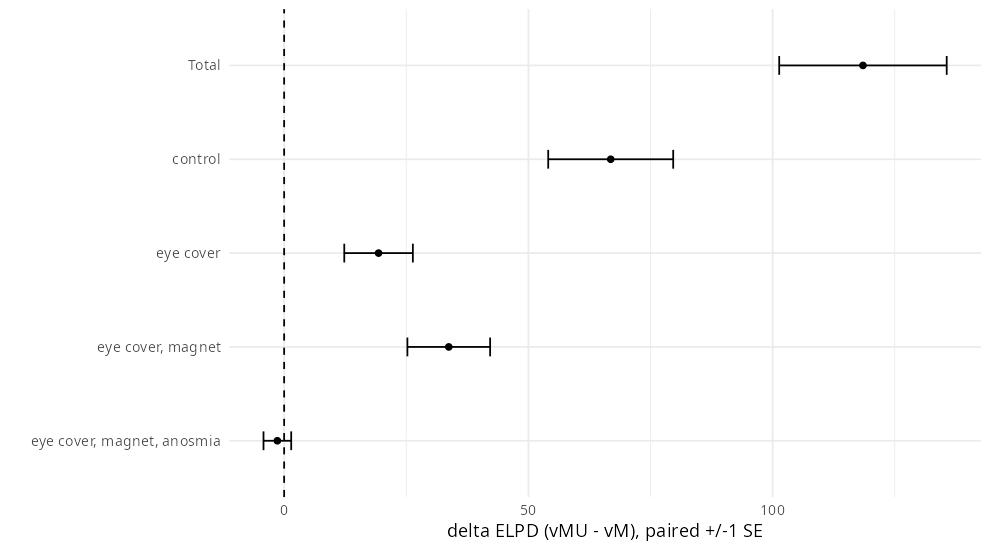

In [33]:
save_figure(p_delta, "psisloo_delta_total_and_by_treatment_vMU_minus_vM", 9, 5)


Total ELPD by model (vMU vs vM), best first.


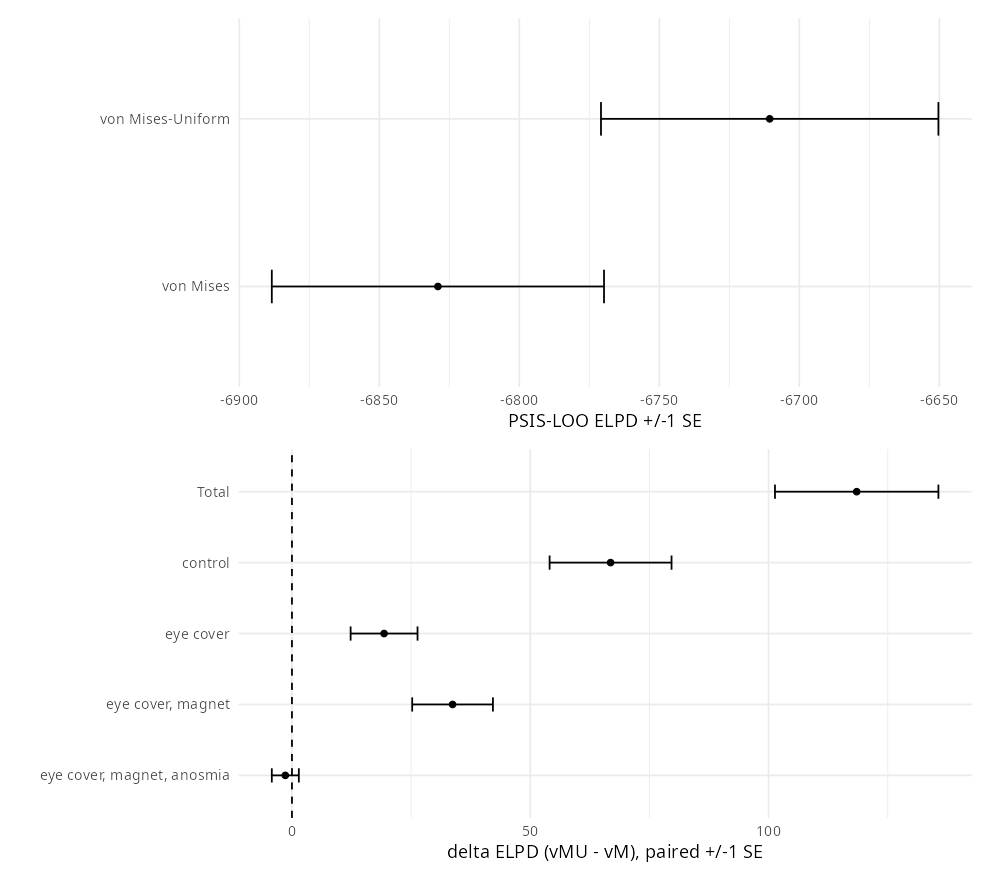

In [34]:
save_figure(patchwork::wrap_plots(p_total, p_delta, ncol = 1), "psisloo_combined", 9, 8)


Pointwise $\Delta$ELPD (vMU $-$ vM) by animal and by treatment — the vMU advantage can be concentrated
in a subset of animals.


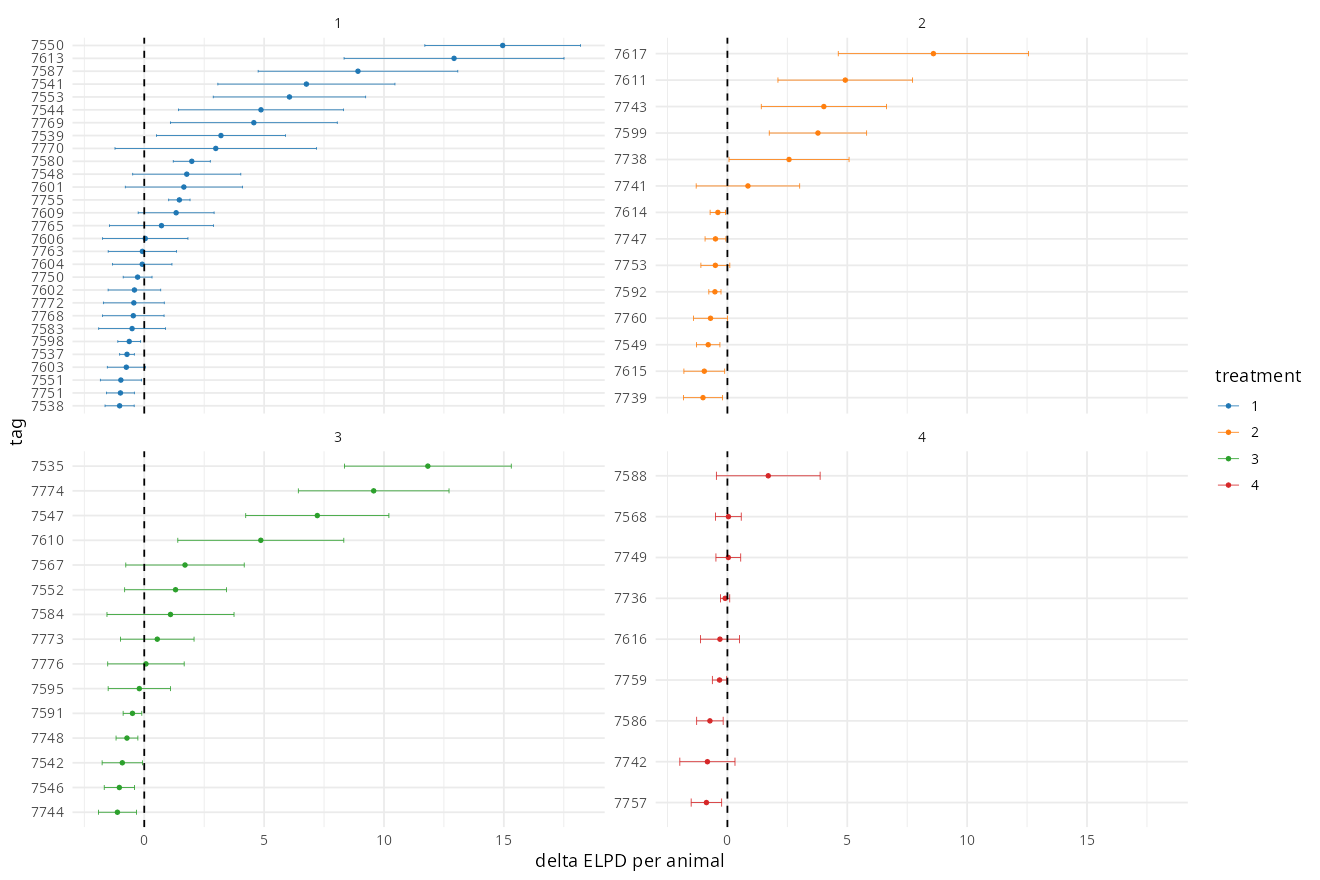

In [35]:
save_figure(p_delta_individual, "psisloo_delta_by_individual_by_treatment_vMU_minus_vM", 12, 8)


## 7. vMU population-level summaries

Population-level vMU summaries: per-treatment polar densities of the goal-relative bearings, showing
the directed + undirected mixture.


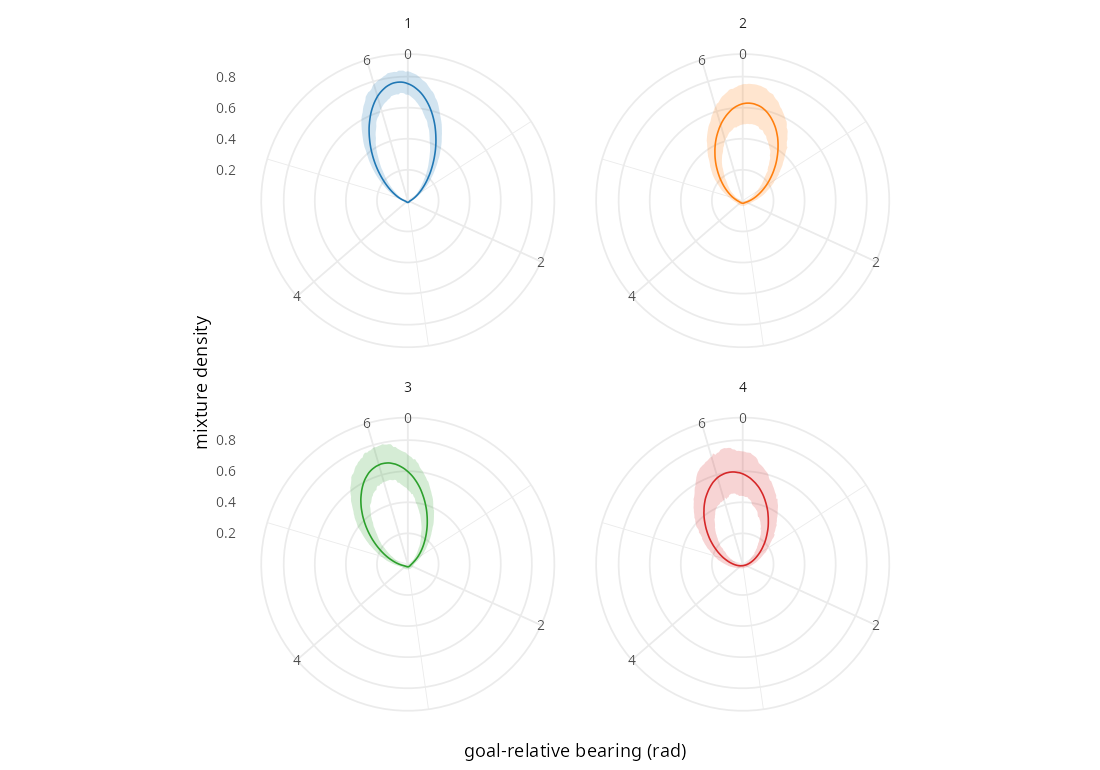

In [36]:
save_figure(p_mixture_polar, "vmum_mixture_full_polar_pdfs_population_only", 10, 7)


Per-treatment population **mixture weight** $p$ (probability a step is goal-directed), goal-directed
alignment to $0^\circ$, and goal-directed $\kappa$, each with posterior means and HDIs.


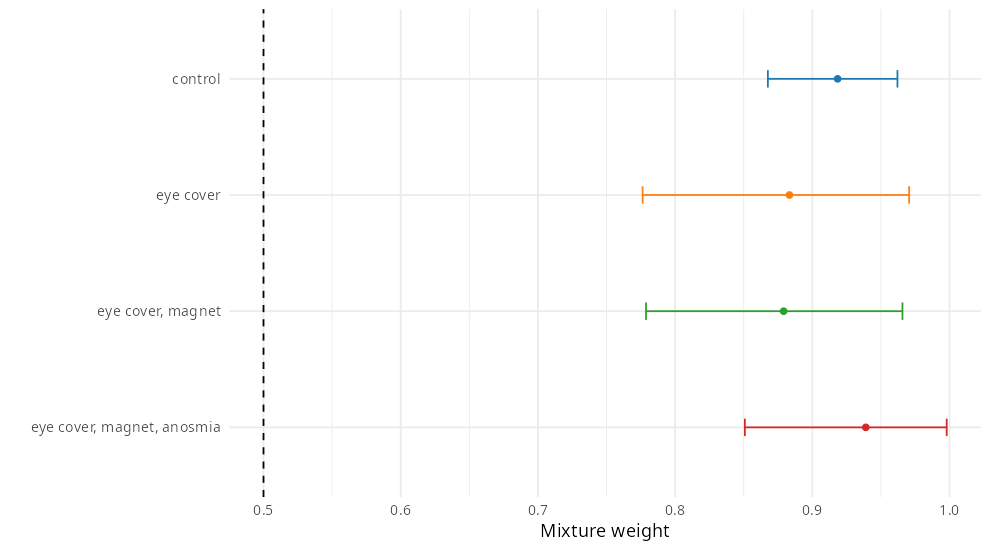

In [37]:
save_figure(p_weight, "fullmodel_mixture_weight_by_treatment_mean_hdi", 9, 5)


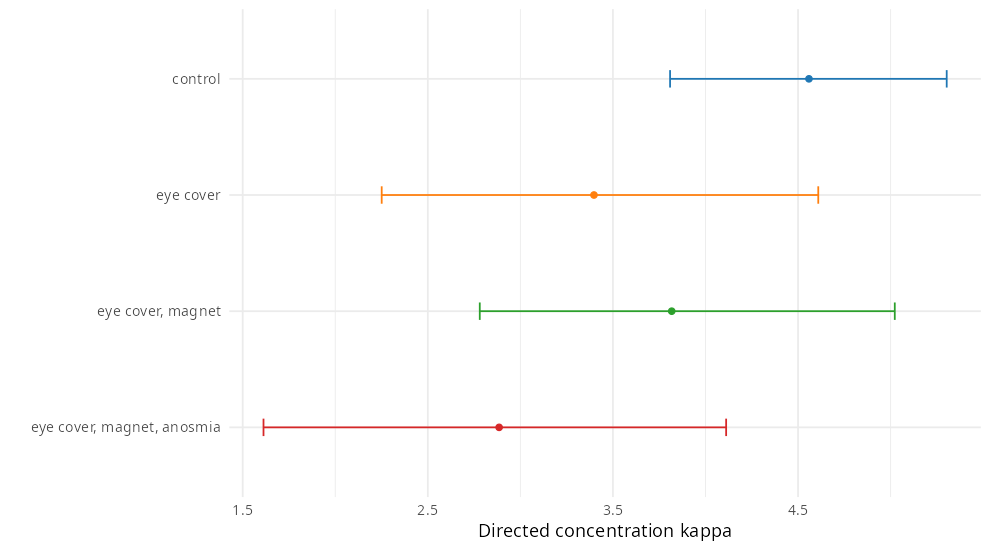

In [38]:
save_figure(p_kappa, "fullmodel_kappa_by_treatment_mean_hdi", 9, 5)


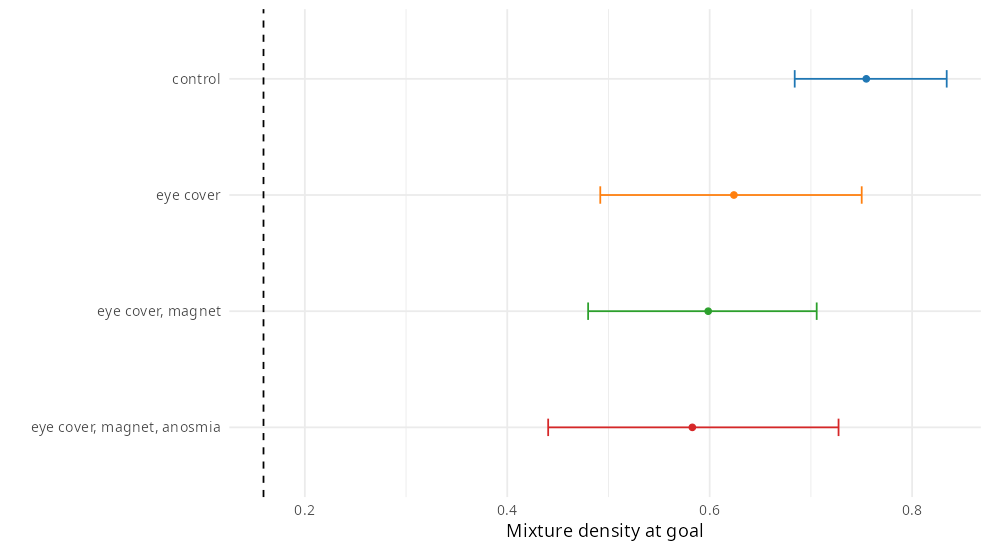

In [39]:
save_figure(p_mix_density, "fullmodel_predictive_density_at_0_mixture_by_treatment_mean_hdi", 9, 5)


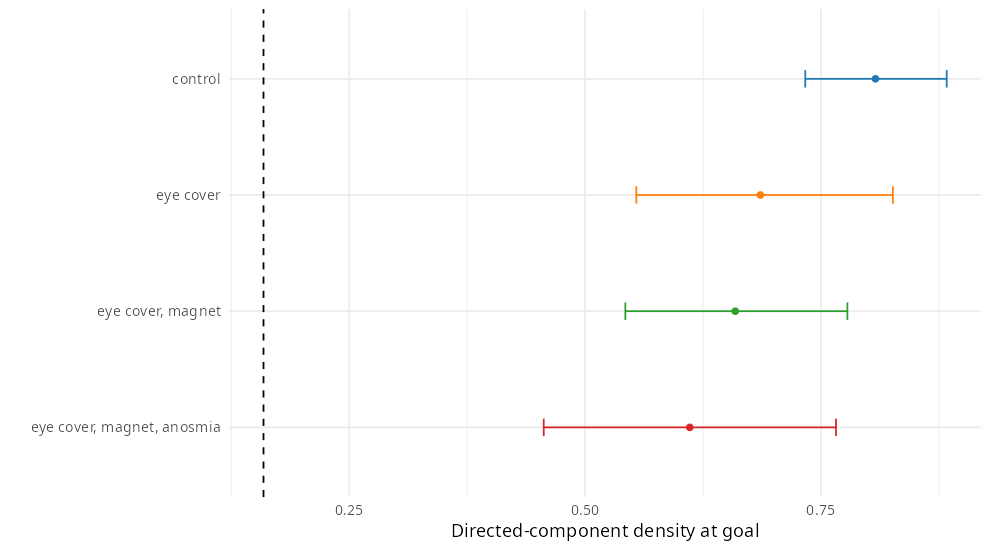

In [40]:
save_figure(p_dir_density, "fullmodel_predictive_density_at_0_directed_component_by_treatment_mean_hdi", 9, 5)


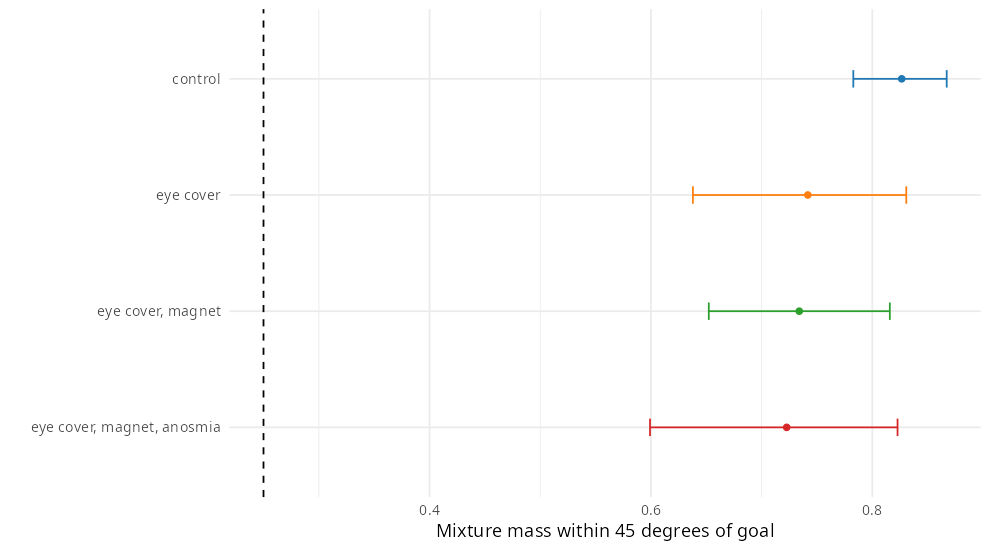

In [41]:
save_figure(p_mass, "fullmodel_predictive_mass_pm45deg_by_treatment_mean_hdi", 9, 5)


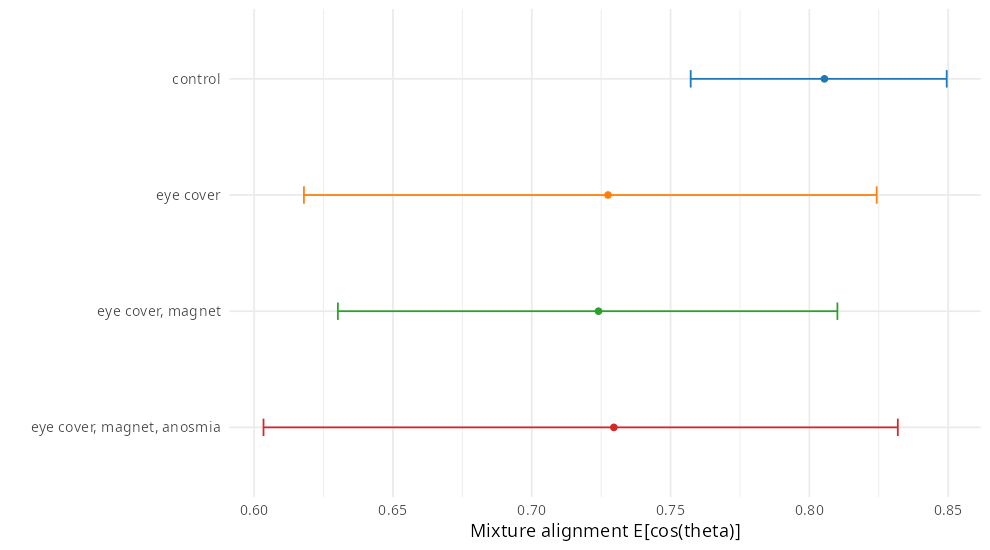

In [42]:
save_figure(p_align, "fullmodel_alignment_to_zero_by_treatment_mean_hdi", 9, 5)


Combined 2x2 summary plot of the out-of-sample comparison against the population-level vMU
parameters.


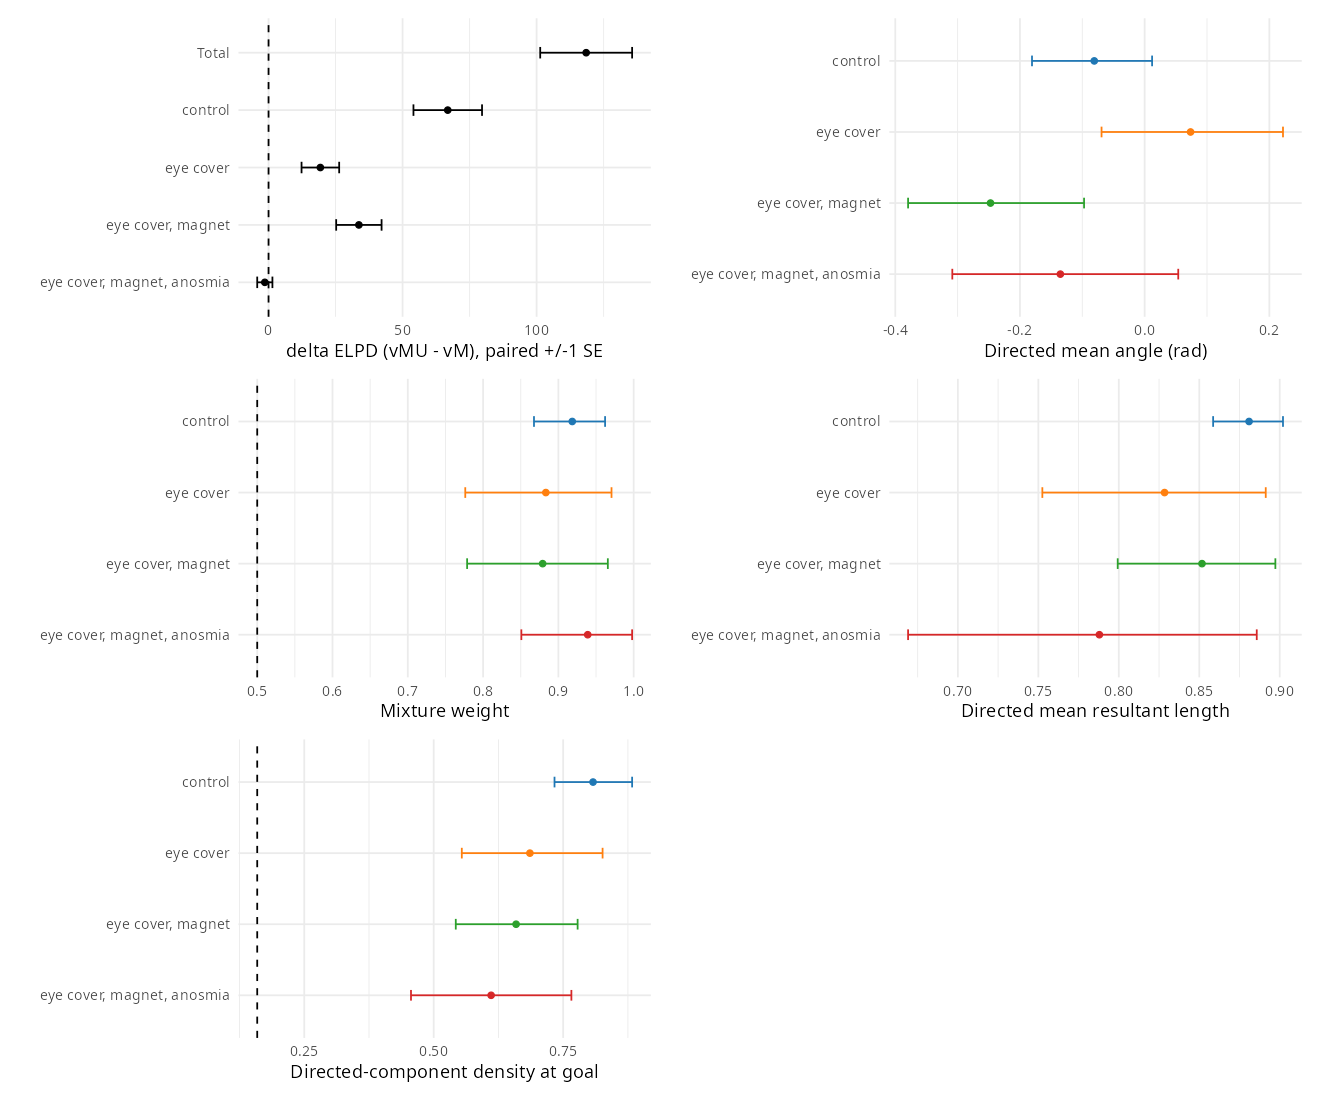

In [43]:
save_figure(patchwork::wrap_plots(p_delta, p_mu, p_weight, p_mrl, p_dir_density, ncol = 2), "psisloo_plus_params_2x2", 12, 10)


Per-treatment predicted posterior density at the goal direction for the vMU (analog of the vM
baseline figure above).


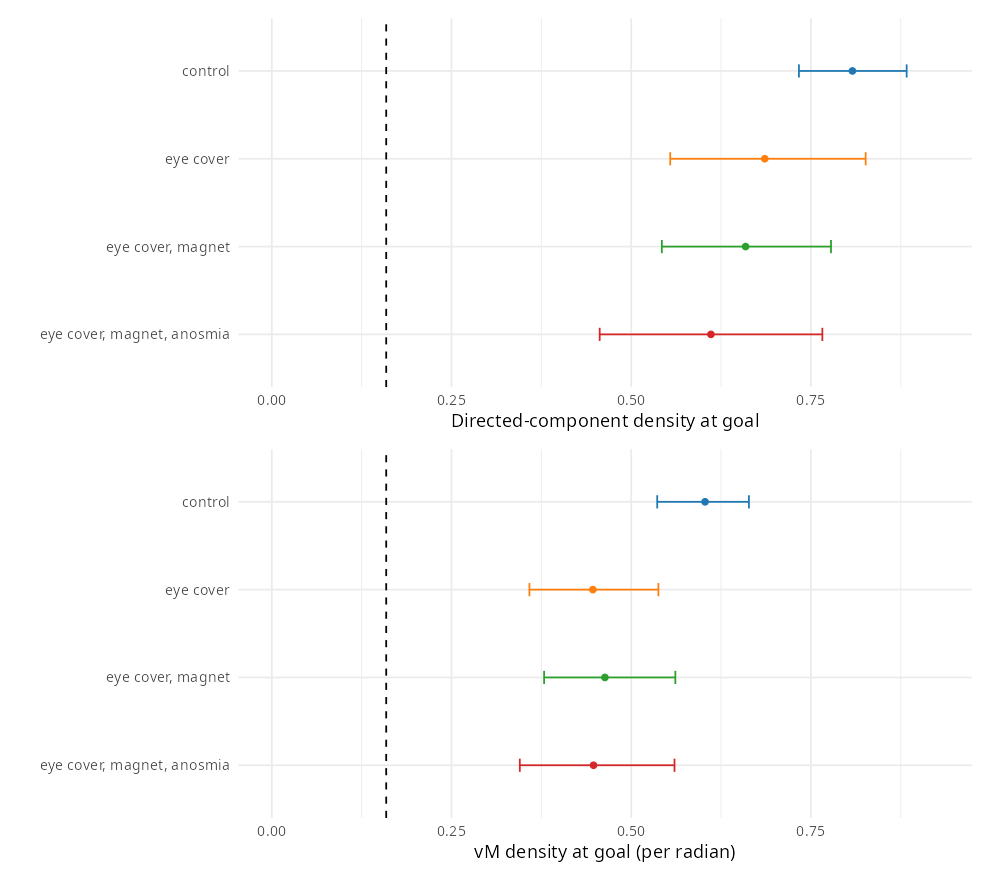

In [44]:
save_figure(patchwork::wrap_plots(p_dir_density + coord_cartesian(xlim = dens_xlim), p_base_density + coord_cartesian(xlim = dens_xlim), ncol = 1), "predictive_density_two_model_comparison_matched_vmu_directed_vs_vm", 9, 8)


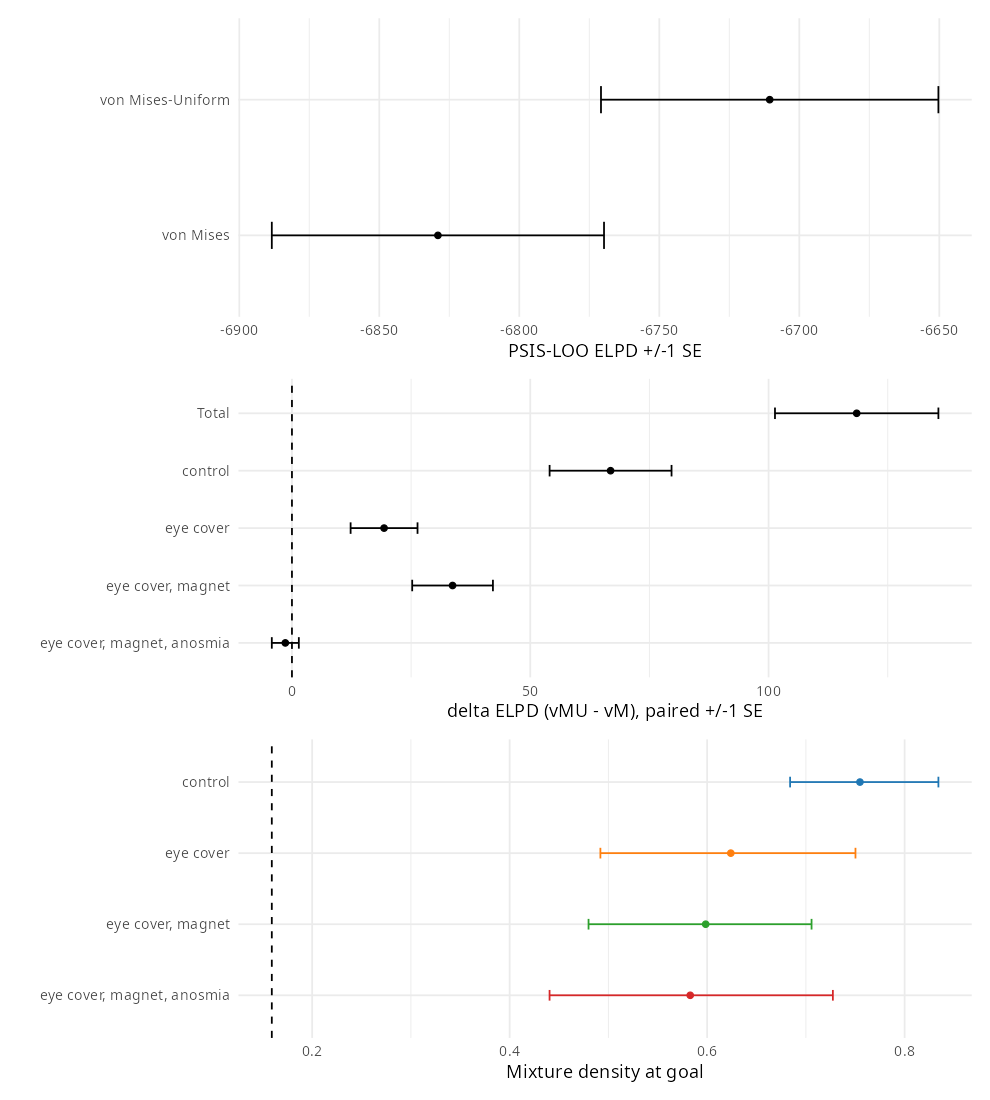

In [45]:
save_figure(patchwork::wrap_plots(p_total, p_delta, p_mix_density, ncol = 1), "psisloo_plus_predictive_density_3panel", 9, 10)


## 8. Per-animal level

Helpers plus **per-animal (tag-level)** vMU summaries: each bat's mixture weight, goal-directed
alignment, and $\kappa$. This is where pronounced between-animal heterogeneity becomes visible.


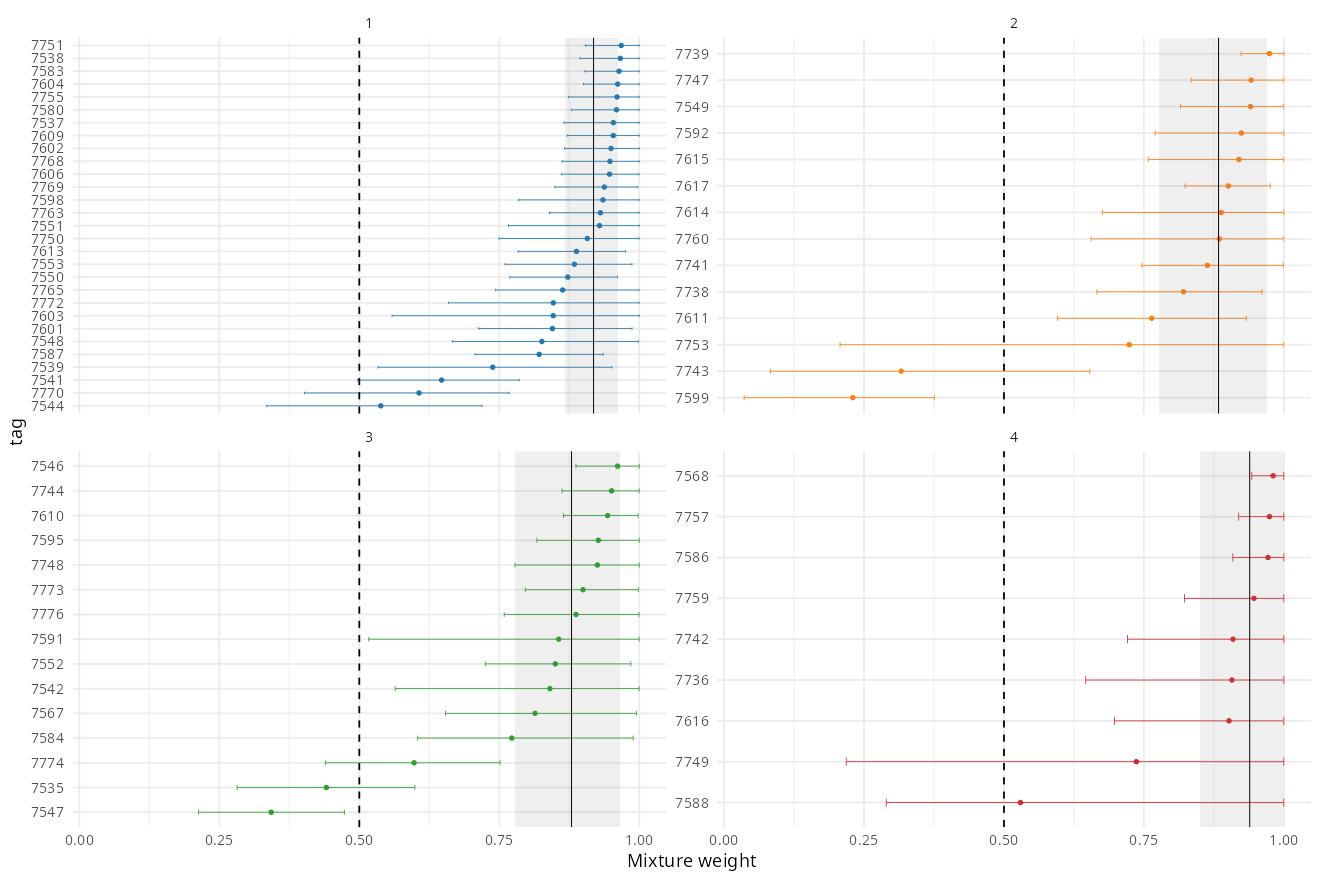

In [46]:
save_figure(tag_hdi_plot("p", "Mixture weight", 0.5), "fullmodel_taglevel_mixture_weight_by_treatment_mean_hdi", 12, 8)


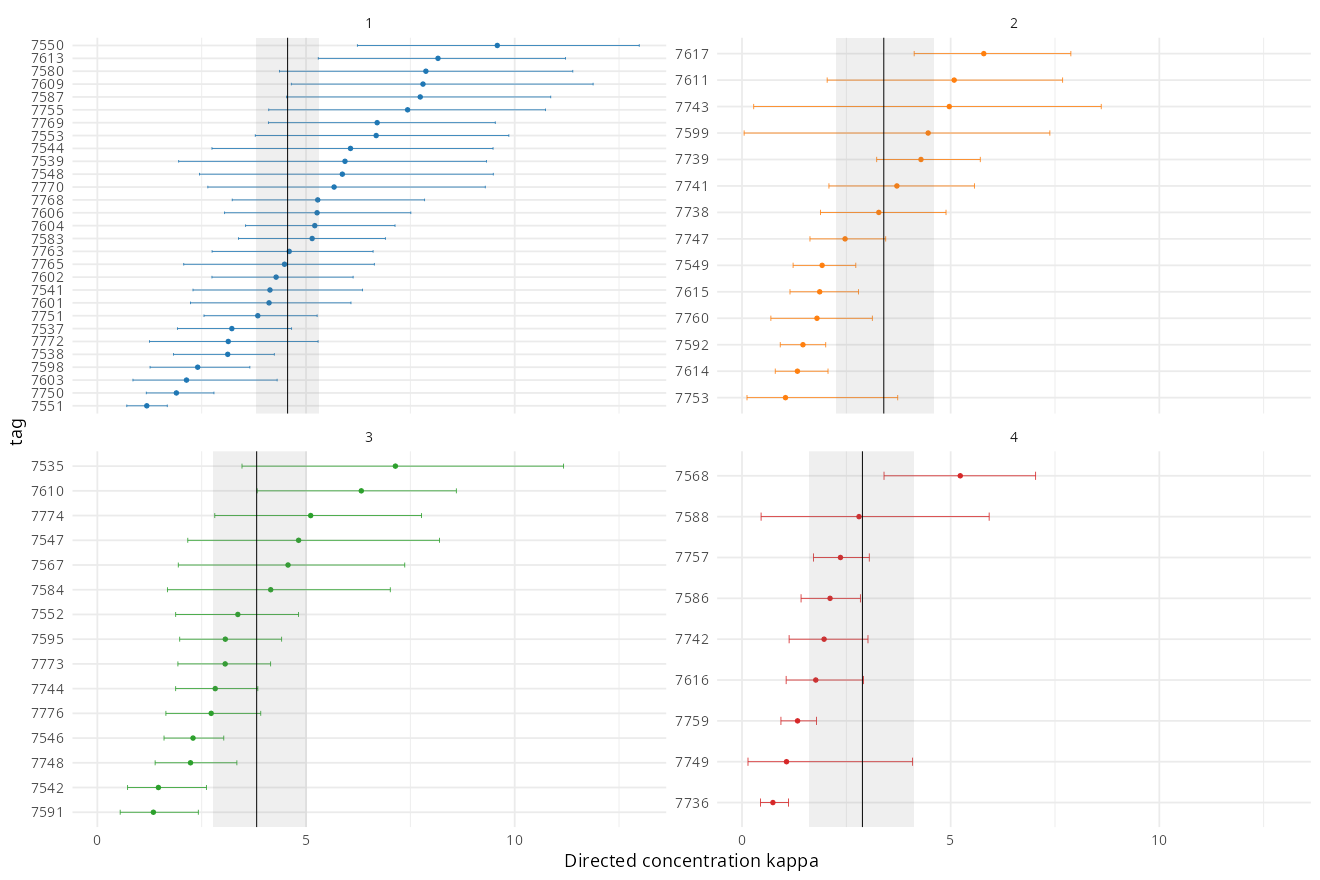

In [47]:
save_figure(tag_hdi_plot("kappa", "Directed concentration kappa"), "fullmodel_taglevel_kappa_by_treatment_mean_hdi", 12, 8)


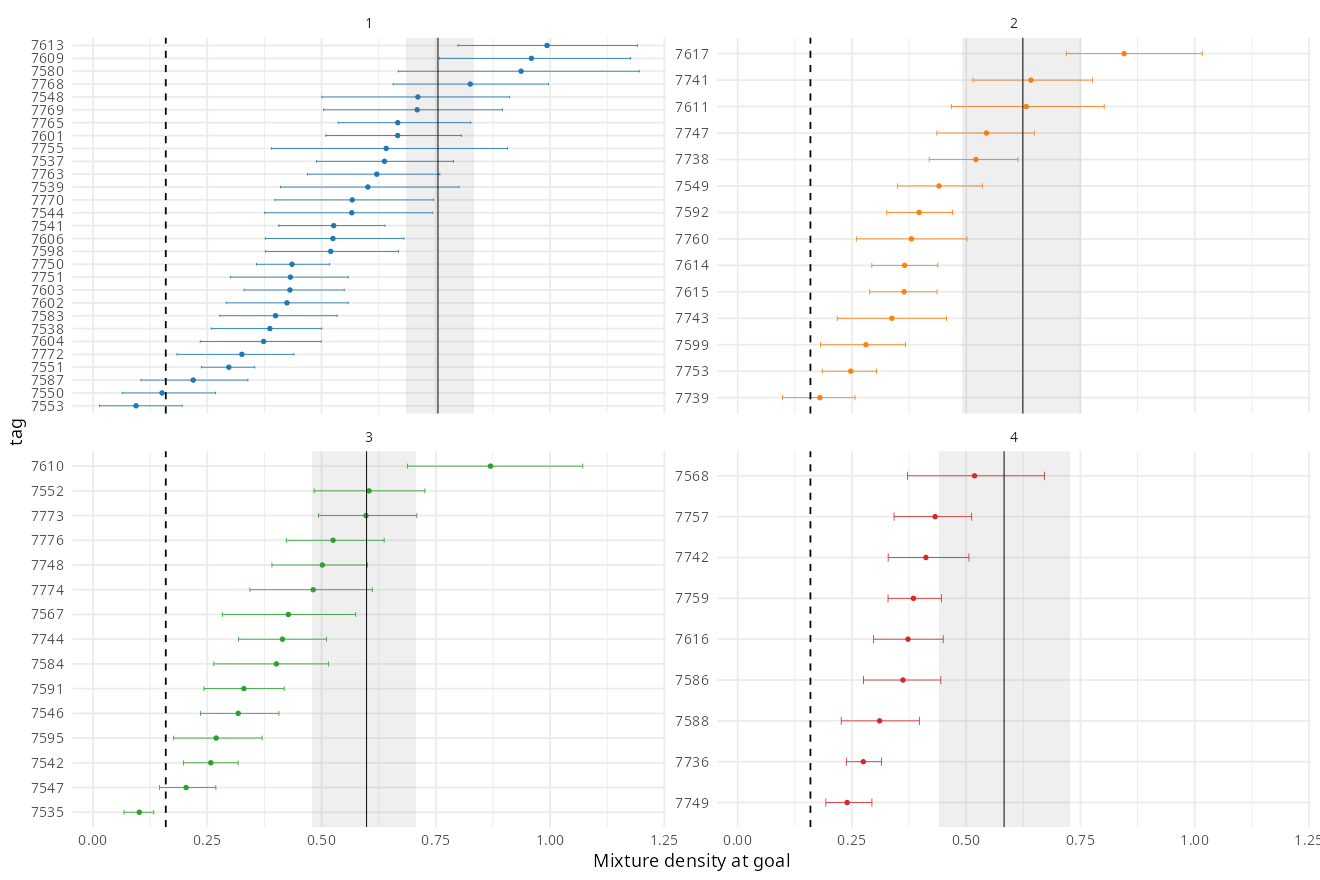

In [48]:
save_figure(tag_hdi_plot("dens0_mix", "Mixture density at goal", 1 / (2 * pi)), "fullmodel_taglevel_predictive_density_at_0_by_treatment_mean_hdi", 12, 8)


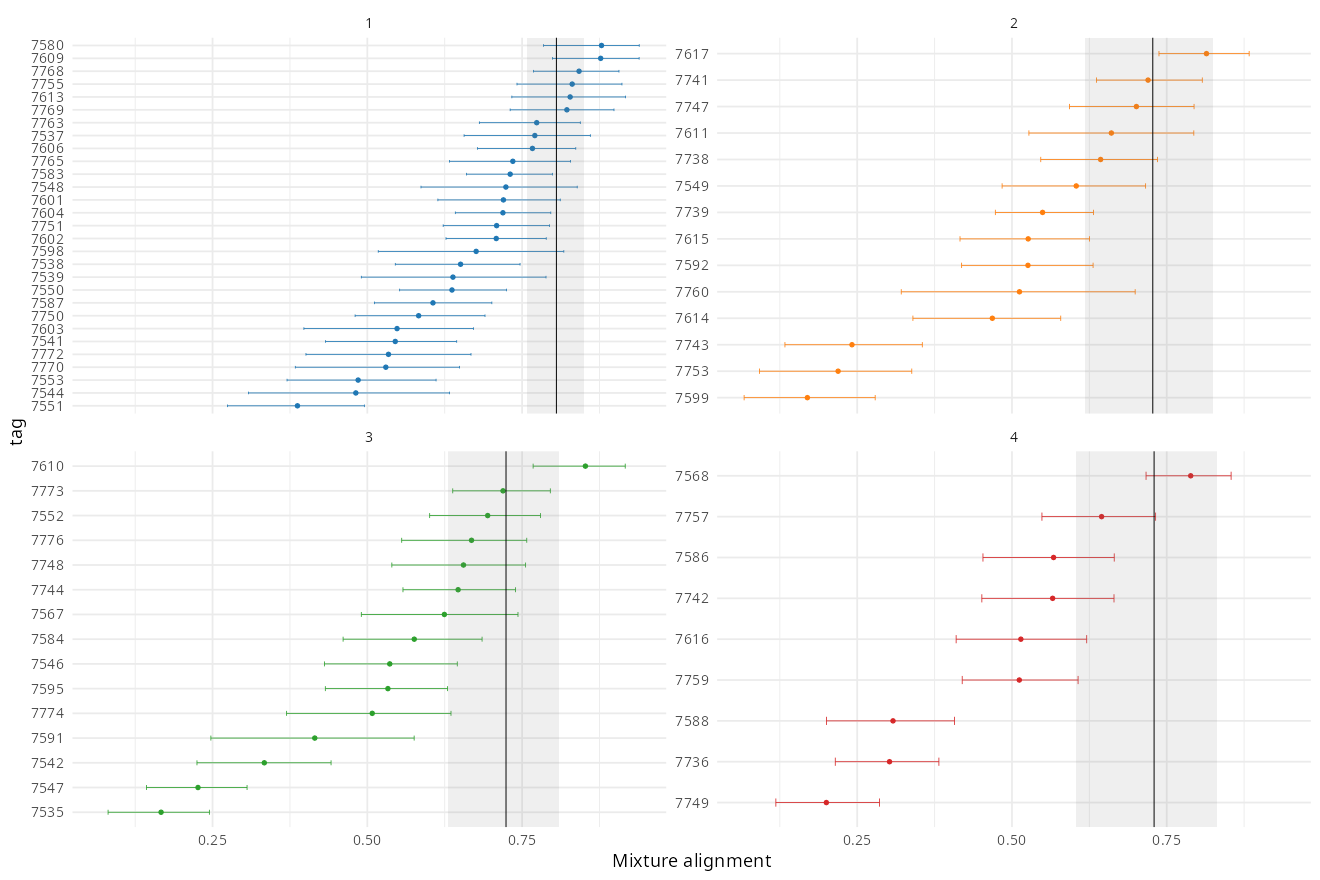

In [49]:
save_figure(tag_hdi_plot("align0", "Mixture alignment"), "fullmodel_taglevel_alignment_to_zero_by_treatment_mean_hdi", 12, 8)


### Posterior predictive checks

The posterior predictive checks (population and individual) resample / bootstrap the goal-relative headings under the vMU and compare them to the observed, per treatment and per animal.


In [50]:
# Full budgets reproduce the source's local bootstrap/draw budgets.
N_BOOT_OBS <- if (quick_run) 150L else 1000L
N_PPC_DRAWS <- if (quick_run) 150L else 4000L
N_INDIV_BOOT <- if (quick_run) 100L else 500L
N_INDIV_DRAWS <- if (quick_run) 100L else 500L
THETA_N <- 360L
angles <- seq(0, 2 * pi, length.out = THETA_N + 1L)[-(THETA_N + 1L)]
bins <- seq(-pi, pi, length.out = 17)
bin_centers <- (head(bins, -1) + tail(bins, -1)) / 2
hist_pdf <- function(y) hist(wrap(y), breaks = bins, plot = FALSE)$density
set.seed(123)
nd <- posterior::ndraws(posterior::as_draws_array(fit_mix))
ppc_ids <- sample.int(nd, min(nd, max(N_PPC_DRAWS, N_INDIV_DRAWS)))
ppc_par <- response_parameters(fit_mix, tag_grid, mixture = TRUE, draw_ids = ppc_ids)
tag_rows <- split(seq_len(nrow(df_track)), df_track$tag)
stopifnot(identical(names(tag_rows), as.character(tag_grid$tag)))
sim_one_tag <- function(j, d) {
  n <- length(tag_rows[[j]])
  goal <- runif(n) < ppc_par$p[j, d]
  vapply(seq_len(n), function(i) {
    if (goal[i]) draw_vm(ppc_par$mu[j, d], ppc_par$kappa[j, d]) else draw_vm(0, KAPPA_UNIFORM)
  }, numeric(1))
}
hier_y <- function(ys) {
  selected <- sample.int(length(ys), length(ys), replace = TRUE)
  unlist(lapply(selected, function(j) {
    y <- ys[[j]]
    y[sample.int(length(y), length(y), replace = TRUE)]
  }), use.names = FALSE)
}
band_table <- function(draws, x, treatment, source, kind, equal_tail = FALSE) {
  # draws are [grid x draws]; summarize each grid row independently.
  bounds <- if (equal_tail) t(apply(draws, 1, quantile, probs = c(0.025, 0.975))) else t(apply(draws, 1, hdi))
  data.frame(x = x, median = apply(draws, 1, median), low = bounds[, 1],
    high = bounds[, 2], treatment = treatment, source = source, kind = kind)
}
population_ppc <- do.call(rbind, lapply(levels(df_track$treatment), function(t) {
  jj <- which(tag_grid$treatment == t)
  observed <- lapply(jj, function(j) df_track$HeadingRadians[tag_rows[[j]]])
  obs_kde <- obs_hist <- pred_kde <- pred_hist <- NULL
  for (b in seq_len(N_BOOT_OBS)) {
    y <- hier_y(observed)
    obs_kde <- cbind(obs_kde, kde_vm(y, angles, 30))
    obs_hist <- cbind(obs_hist, hist_pdf(y))
  }
  for (d in seq_len(min(N_PPC_DRAWS, ncol(ppc_par$mu)))) {
    replicated <- lapply(jj, function(j) sim_one_tag(j, d))
    y <- hier_y(replicated)
    pred_kde <- cbind(pred_kde, kde_vm(y, angles, 30))
    pred_hist <- cbind(pred_hist, hist_pdf(y))
  }
  rbind(band_table(obs_kde, angles, t, "observed bootstrap", "KDE"),
    band_table(pred_kde, angles, t, "posterior predictive", "KDE"),
    band_table(obs_hist, bin_centers, t, "observed bootstrap", "histogram"),
    band_table(pred_hist, bin_centers, t, "posterior predictive", "histogram"))
}))
population_ppc$treatment <- factor(population_ppc$treatment, levels = 1:4)
p_population_ppc <- ggplot(population_ppc, aes(x, median, colour = source, fill = source)) +
  geom_ribbon(aes(ymin = low, ymax = high), alpha = 0.15, colour = NA) +
  geom_line(linewidth = 0.4) + facet_grid(kind ~ treatment, scales = "free_x") +
  labs(x = "goal-relative bearing (rad)", y = "density") + theme(legend.position = "bottom")

individual_ppc <- do.call(rbind, lapply(seq_along(tag_rows), function(j) {
  set.seed(10000L + j - 1L)
  y <- df_track$HeadingRadians[tag_rows[[j]]]
  observed <- replicate(N_INDIV_BOOT, {
    boot <- y[sample.int(length(y), length(y), replace = TRUE)]
    kde_vm(boot, angles, 15)
  })
  predicted <- vapply(seq_len(min(N_INDIV_DRAWS, ncol(ppc_par$mu))),
    function(d) kde_vm(sim_one_tag(j, d), angles, 15), numeric(length(angles)))
  z <- rbind(band_table(observed, angles, tag_grid$treatment[j], "observed bootstrap", "KDE", TRUE),
    band_table(predicted, angles, tag_grid$treatment[j], "posterior predictive", "KDE", TRUE))
  z$tag <- as.character(tag_grid$tag[j])
  z
}))
peak <- max(individual_ppc$high)
p_individual_ppc <- ggplot(individual_ppc,
  aes(x, 1 + median / peak, colour = source, fill = source, group = source)) +
  geom_ribbon(aes(ymin = 1 + low / peak, ymax = 1 + high / peak), alpha = 0.15, colour = NA) +
  geom_path(linewidth = 0.25) + facet_wrap(~ tag, ncol = 8) +
  scale_x_continuous(limits = c(0, 2 * pi), expand = c(0, 0)) + coord_polar() +
  labs(x = "goal-relative bearing (rad)", y = "1 + scaled density") + theme(legend.position = "bottom")


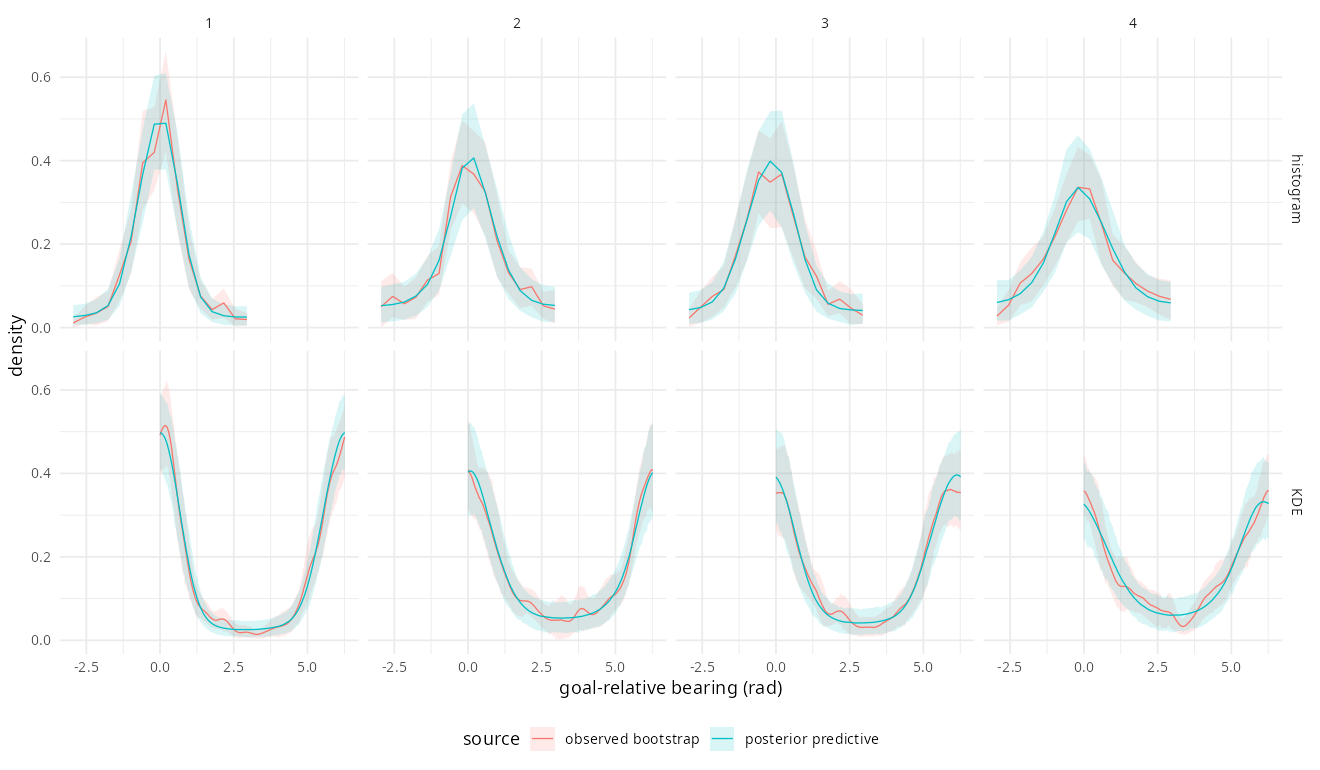

In [51]:
save_figure(p_population_ppc, "bat_population_ppc_by_treatment", 12, 7)


Individual PPC: bootstrap vs posterior KDE of the goal-directed component per animal.


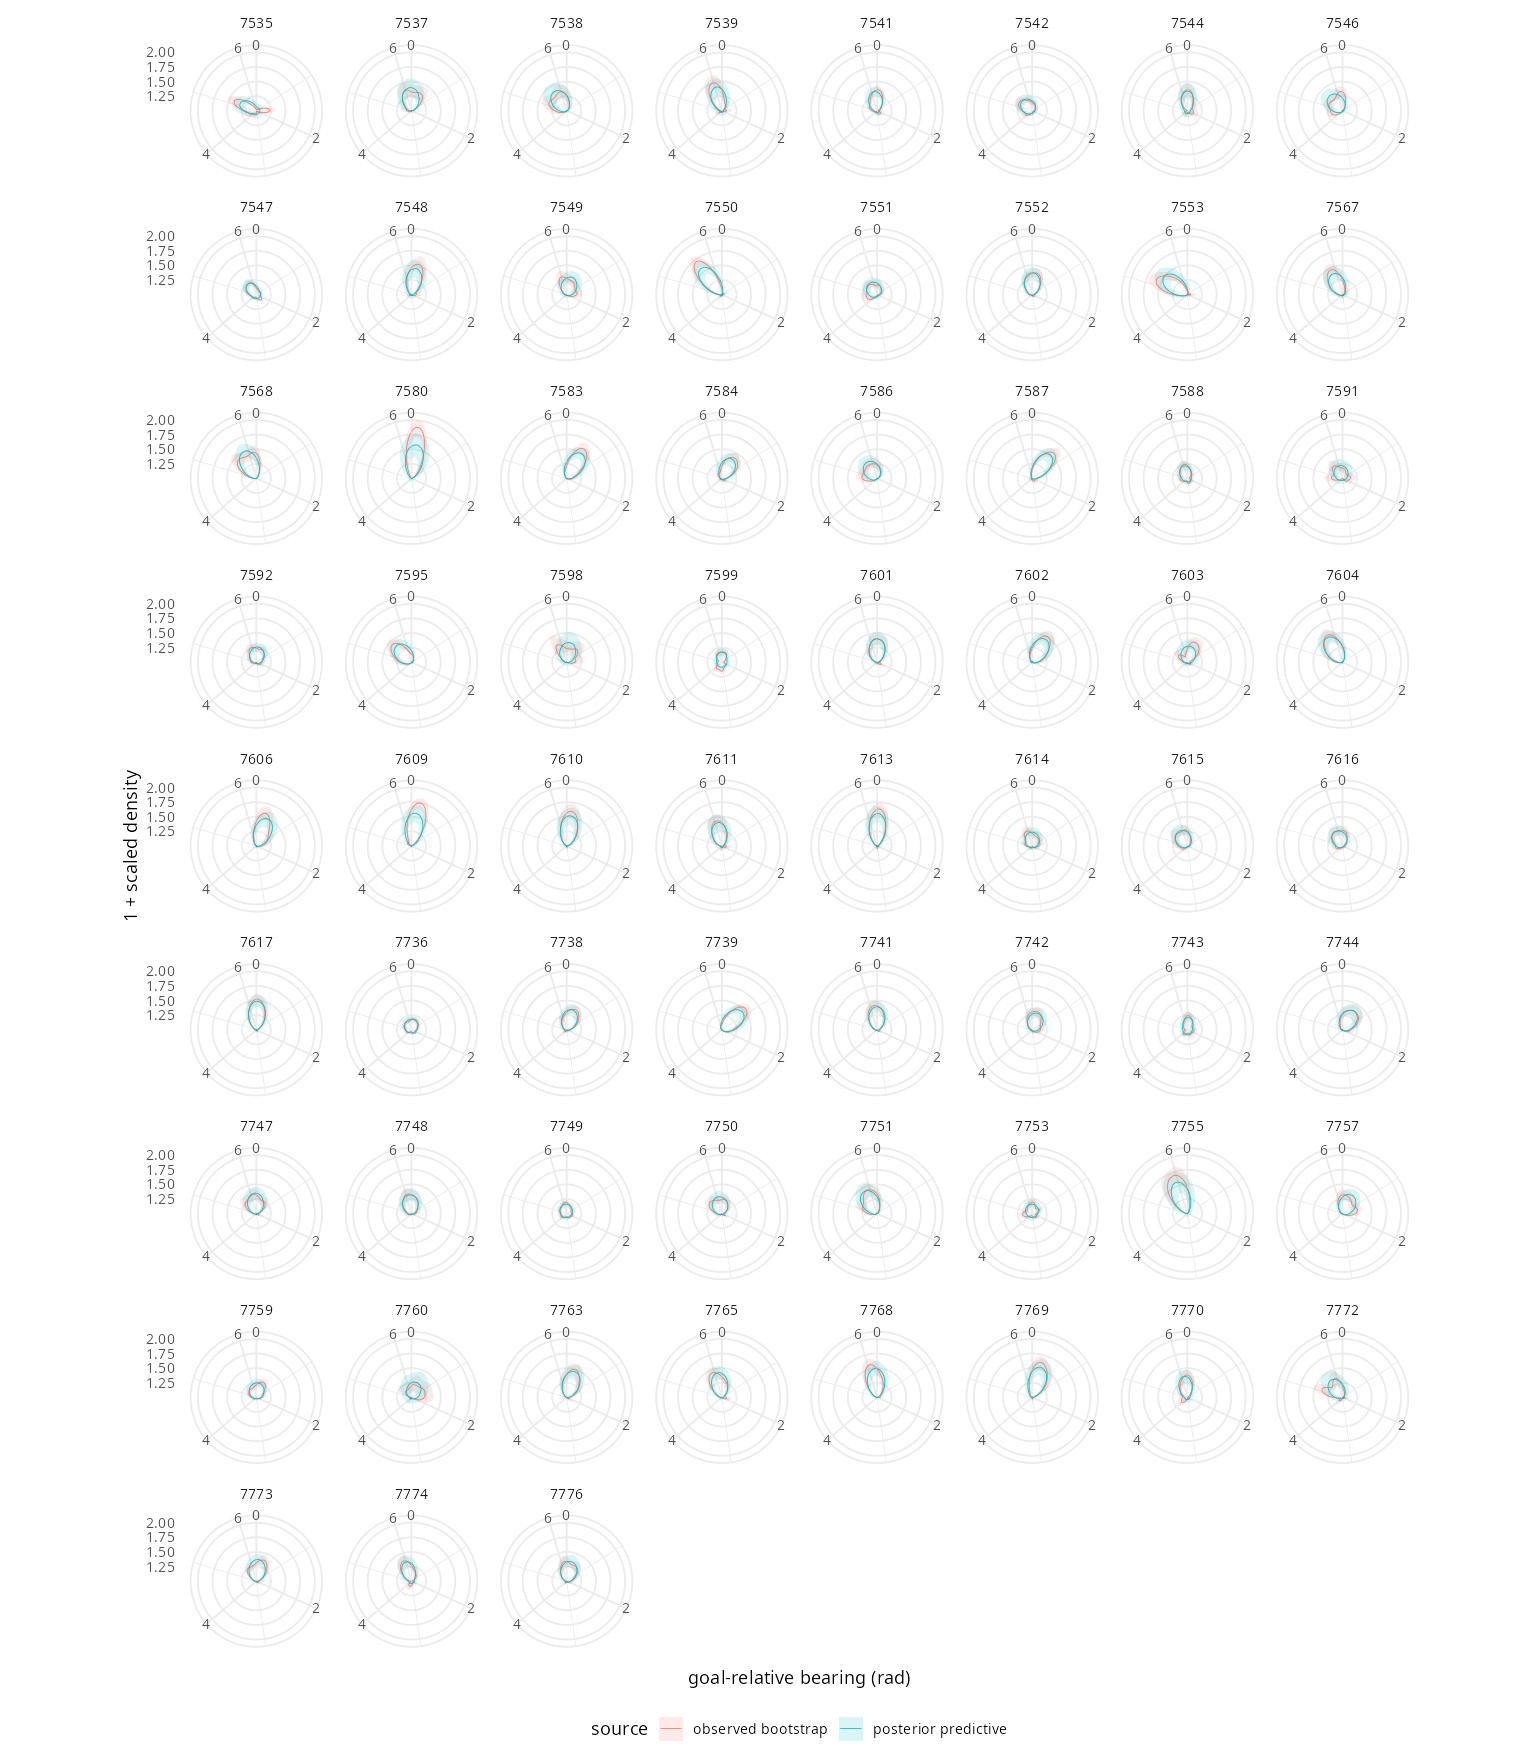

In [52]:
save_figure(p_individual_ppc, "bat_individual_ppc_bootstrap_vs_ppc_kde", 14, 16)


## 9. Goal-directedness along the trajectory

Posterior probability that each step belongs to the **directed (goal-seeking) component**
($p_{goal}$), plotted along each trajectory (by distance / progress toward the goal). Directedness is
expected to be lower early in a flight (localization / exploration) and higher near the endpoint
(homing).


In [53]:
set.seed(123)
RESP_DRAWS <- if (quick_run) 200L else 2000L
resp_ids <- sample.int(nd, min(nd, RESP_DRAWS))
resp <- matrix(NA_real_, nrow = nrow(df_track), ncol = length(resp_ids))
for (start in seq.int(1L, nrow(df_track), by = 128L)) {
  ii <- seq.int(start, min(start + 127L, nrow(df_track)))
  par <- response_parameters(fit_mix, df_track[ii, ], mixture = TRUE, draw_ids = resp_ids)
  y <- matrix(rep(df_track$HeadingRadians[ii], length(resp_ids)), nrow = length(ii))
  log_goal <- vm_logpdf(y, par$mu, par$kappa)
  # Match the effective append_pgoal_post_to_df helper called by c94/c99:
  # a near-uniform VM proxy and probability-space posterior summaries.
  w <- pmin(1 - 1e-12, pmax(1e-12, par$p))
  log_flat <- vm_logpdf(y, 0, KAPPA_UNIFORM)
  resp[ii, ] <- plogis(qlogis(w) + log_goal - log_flat)
}
stopifnot(all(is.finite(resp)), all(resp >= 0 & resp <= 1))
# The earlier unused helper has a different logit-space convention; use
# the later effective helper that the Python notebook actually calls.
df_track$p_goal_post_mean <- rowMeans(resp)
resp_hdi <- t(apply(resp, 1, hdi))
df_track$p_goal_post_lo <- resp_hdi[, 1]
df_track$p_goal_post_hi <- resp_hdi[, 2]
# The maps' source joins by per-tag step index; join by (tag,time) here to
# avoid shifting probabilities at rows removed from the modeling table.
key <- function(tag, time) paste(tag, sprintf("%.12f", time), sep = ":")
stopifnot(!anyDuplicated(key(df_track$tag, df_track$time)))
join <- match(key(segments$tag, segments$time), key(df_track$tag, df_track$time))
prob_segments <- segments
prob_segments$p <- df_track$p_goal_post_mean[join]
p_probability_map <- map_base() +
  geom_segment(data = prob_segments, aes(x, y, xend = xend, yend = yend, colour = p, linetype = gap),
    linewidth = 0.4, alpha = 0.9) + facet_wrap(~ treatment) +
  scale_colour_viridis_c(limits = c(0, 1), na.value = "grey70") +
  scale_linetype_manual(values = c("0" = "solid", "1" = "dashed")) +
  labs(colour = "directed-component probability")


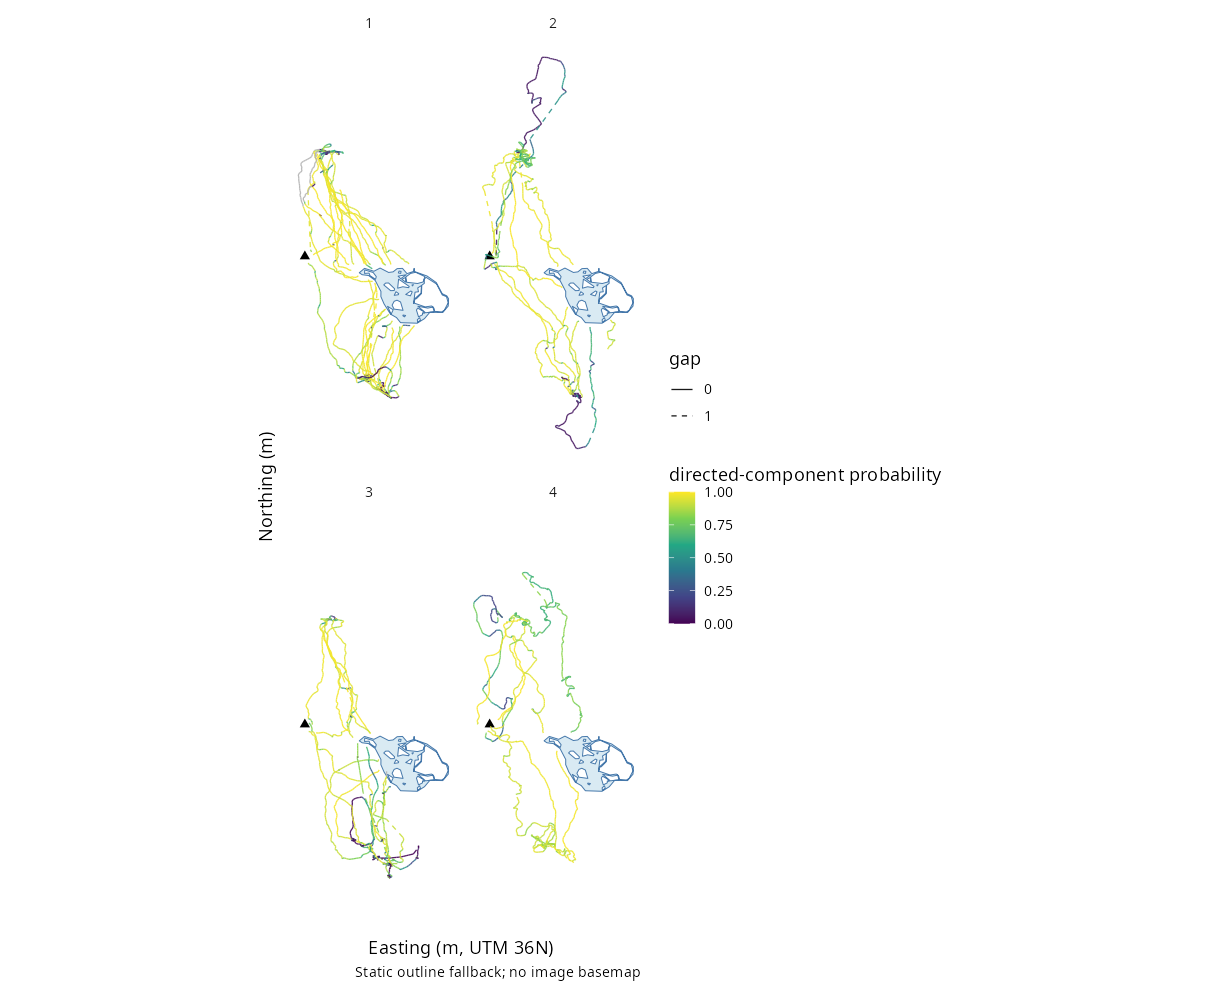

In [54]:
save_figure(p_probability_map, "treatment_panels_tracks_pgoal", 11, 9)


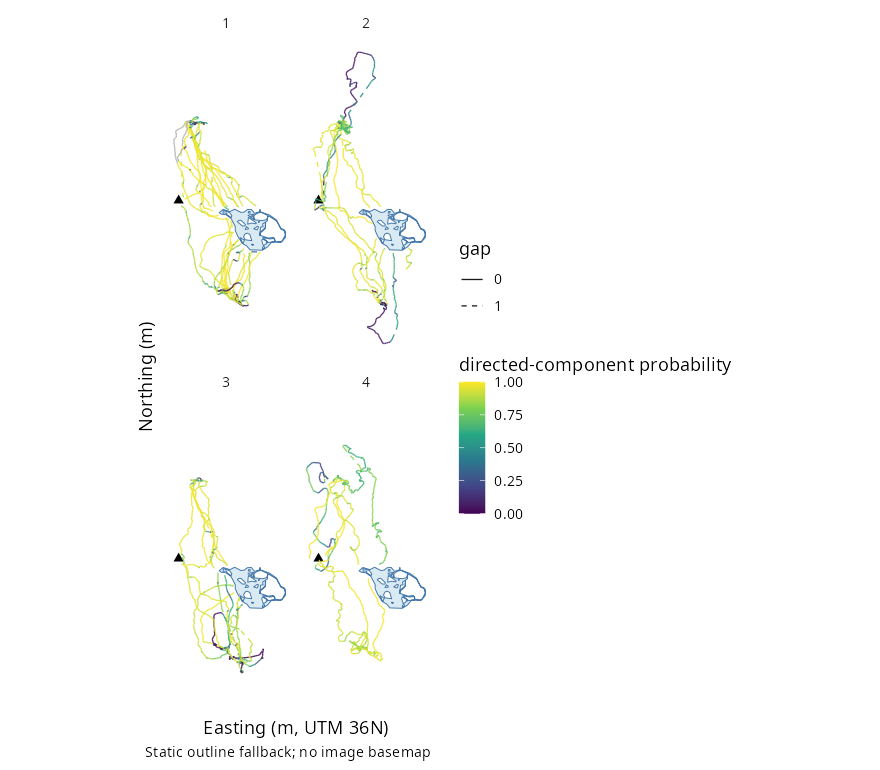

In [55]:
save_figure(p_probability_map, "treatment_panels_tracks_pgoal_small_bigfont", 8, 7)


Population-level $p_{goal}$ as a function of distance from the flight's endpoint — lower early, higher
as the animal approaches its goal.


In [56]:
# Gaussian smoothing per tag, equal-tag averaging per posterior draw,
# range/weight truncation, and weighted population post-smoothing.
smooth_population <- function(draws, grid, counts, bandwidth = 240) {
  spacing <- median(diff(grid))
  sigma <- bandwidth / spacing
  if (sigma < 0.5) return(draws)
  radius <- ceiling(4 * sigma)
  offsets <- seq.int(-radius, radius)
  kernel <- exp(-0.5 * (offsets / sigma)^2)
  safe <- draws
  safe[!is.finite(safe)] <- 0
  out <- matrix(NA_real_, nrow(draws), ncol(draws))
  for (g in seq_along(grid)) {
    ii <- g + offsets
    valid <- ii >= 1L & ii <= length(grid)
    w <- kernel[valid] * counts[ii[valid]]
    if (sum(w) > 1e-12) out[g, ] <- colSums(safe[ii[valid], , drop = FALSE] * w) / sum(w)
  }
  out
}
summarize_curve <- function(curve, grid, treatment, tag = NA_character_) {
  valid <- rowSums(is.finite(curve)) == ncol(curve)
  if (!any(valid)) return(NULL)
  z <- curve[valid, , drop = FALSE]
  bounds <- t(apply(z, 1, hdi))
  data.frame(x = grid[valid], mean = rowMeans(z), low = bounds[, 1], high = bounds[, 2],
    treatment = treatment, tag = tag)
}
make_curves <- function(kind) {
  x <- df_track$dist_to_dest_grad_m
  if (kind == "steps_from_end") {
    x <- ave(seq_len(nrow(df_track)), df_track$tag,
      FUN = function(ii) (seq_along(ii) - length(ii)) * 60)
  }
  G <- if (quick_run) 400L else 2000L
  population <- individual <- list()
  for (t in levels(df_track$treatment)) {
    eligible <- which(df_track$treatment == t & is.finite(x))
    if (kind == "steps_from_end") eligible <- eligible[x[eligible] >= -110 * 60]
    grid <- seq(min(x[eligible]), max(x[eligible]), length.out = G)
    total <- matrix(0, G, ncol(resp))
    counts <- numeric(G)
    tags <- split(eligible, droplevels(df_track$tag[eligible]))
    for (tag in names(tags)) {
      ii <- tags[[tag]]
      if (length(ii) < 2L) next
      # Explicit [grid x observations] kernel, [grid x draws] prediction.
      weights <- exp(-0.5 * (outer(grid, x[ii], "-") / 120)^2)
      denominator <- rowSums(weights) + 1e-12
      curve <- (weights %*% resp[ii, , drop = FALSE]) / denominator
      valid <- grid >= min(x[ii]) & grid <= max(x[ii]) &
        denominator >= 0.01 * max(denominator)
      total[valid, ] <- total[valid, , drop = FALSE] + curve[valid, , drop = FALSE]
      counts[valid] <- counts[valid] + 1L
      curve[!valid, ] <- NA_real_
      individual[[paste(t, tag)]] <- summarize_curve(curve, grid, t, tag)
    }
    curve <- total / pmax(counts, 1)
    curve[counts < 2L, ] <- NA_real_
    support <- counts
    support[counts < 2L] <- 0
    curve <- smooth_population(curve, grid, support, bandwidth = 240)
    curve[counts < 2L, ] <- NA_real_
    population[[t]] <- summarize_curve(curve, grid, t)
  }
  list(population = do.call(rbind, population), individual = do.call(rbind, individual))
}
distance_curves <- make_curves("distance")
end_curves <- make_curves("steps_from_end")
curve_plot <- function(curves, individual = FALSE, reverse = FALSE) {
  x <- if (individual) curves$individual else curves$population
  x$treatment <- factor(x$treatment, levels = 1:4)
  p <- ggplot(x, aes(x, mean, colour = treatment,
    group = if (individual) tag else treatment, fill = treatment)) +
    geom_ribbon(aes(ymin = low, ymax = high), alpha = if (individual) 0.06 else 0.2, colour = NA) +
    geom_line(linewidth = if (individual) 0.25 else 0.6) +
    scale_colour_manual(values = treatment_colors) + scale_fill_manual(values = treatment_colors) +
    labs(x = if (reverse) "Distance to destination (m)" else "Cumulative path distance from end (m)",
         y = "Directed-component probability") + theme(legend.position = "bottom")
  if (individual) p <- p + facet_wrap(~ treatment)
  if (reverse) {
    p <- p + scale_x_reverse()
  } else {
    p <- p + scale_x_continuous(limits = c(-110 * 60, 0), labels = function(x) abs(x))
  }
  p
}
p_curve_distance <- curve_plot(distance_curves, reverse = TRUE)
p_curve_end <- curve_plot(end_curves)
p_tag_distance <- curve_plot(distance_curves, individual = TRUE, reverse = TRUE)
p_tag_end <- curve_plot(end_curves, individual = TRUE)


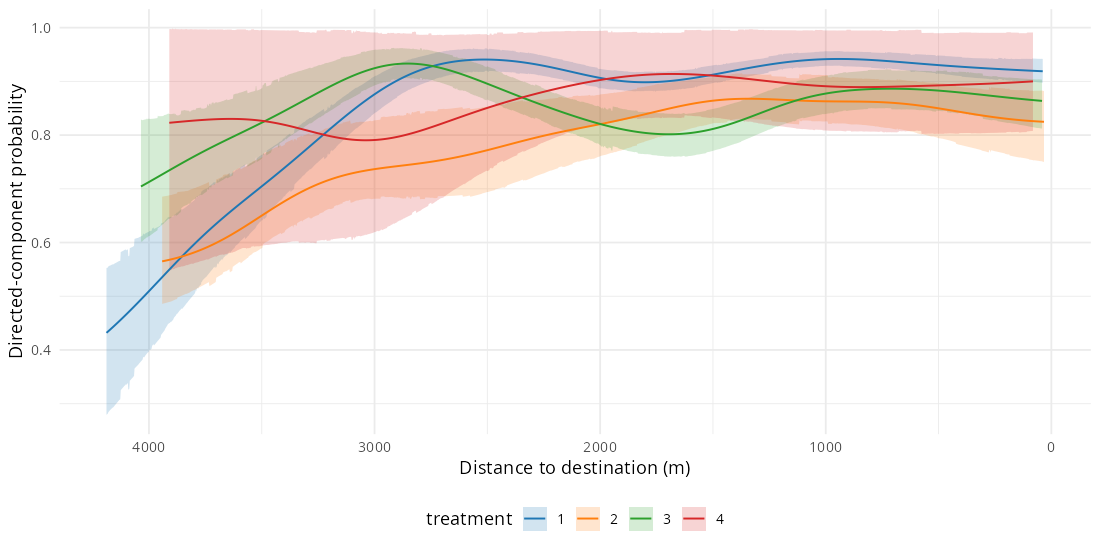

In [57]:
save_figure(p_curve_distance, "p_goal_pop_kernel_distance_TRUNC_SMOOTH", 10, 5)


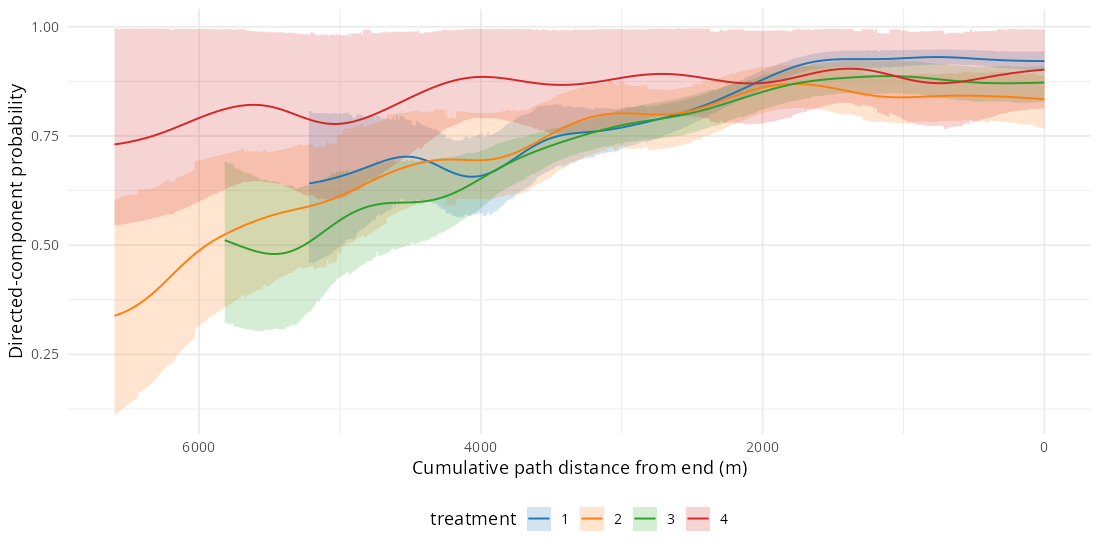

In [58]:
save_figure(p_curve_end, "p_goal_pop_kernel_distFromEndM_TRUNC_SMOOTH", 10, 5)


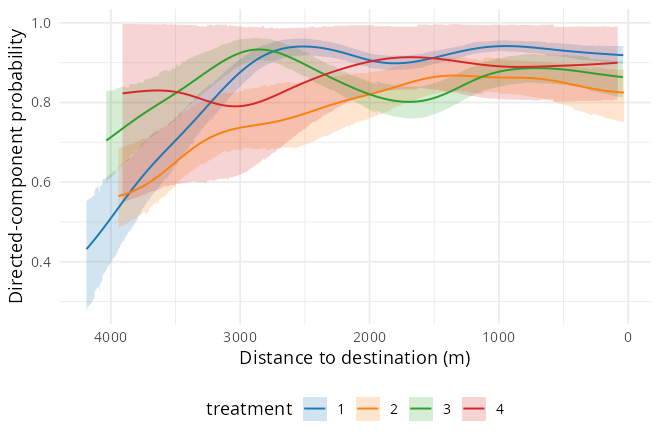

In [59]:
save_figure(p_curve_distance, "p_goal_pop_kernel_distance_TRUNC_SMOOTH_compact", 6, 4)


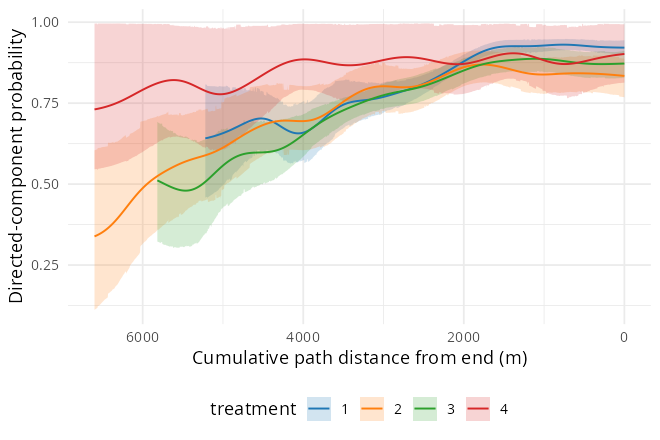

In [60]:
save_figure(p_curve_end, "p_goal_pop_kernel_distFromEndM_TRUNC_SMOOTH_compact", 6, 4)


Per-animal (faceted) $p_{goal}$ along the flight, showing the heterogeneity in when each bat commits
to goal-directed travel.


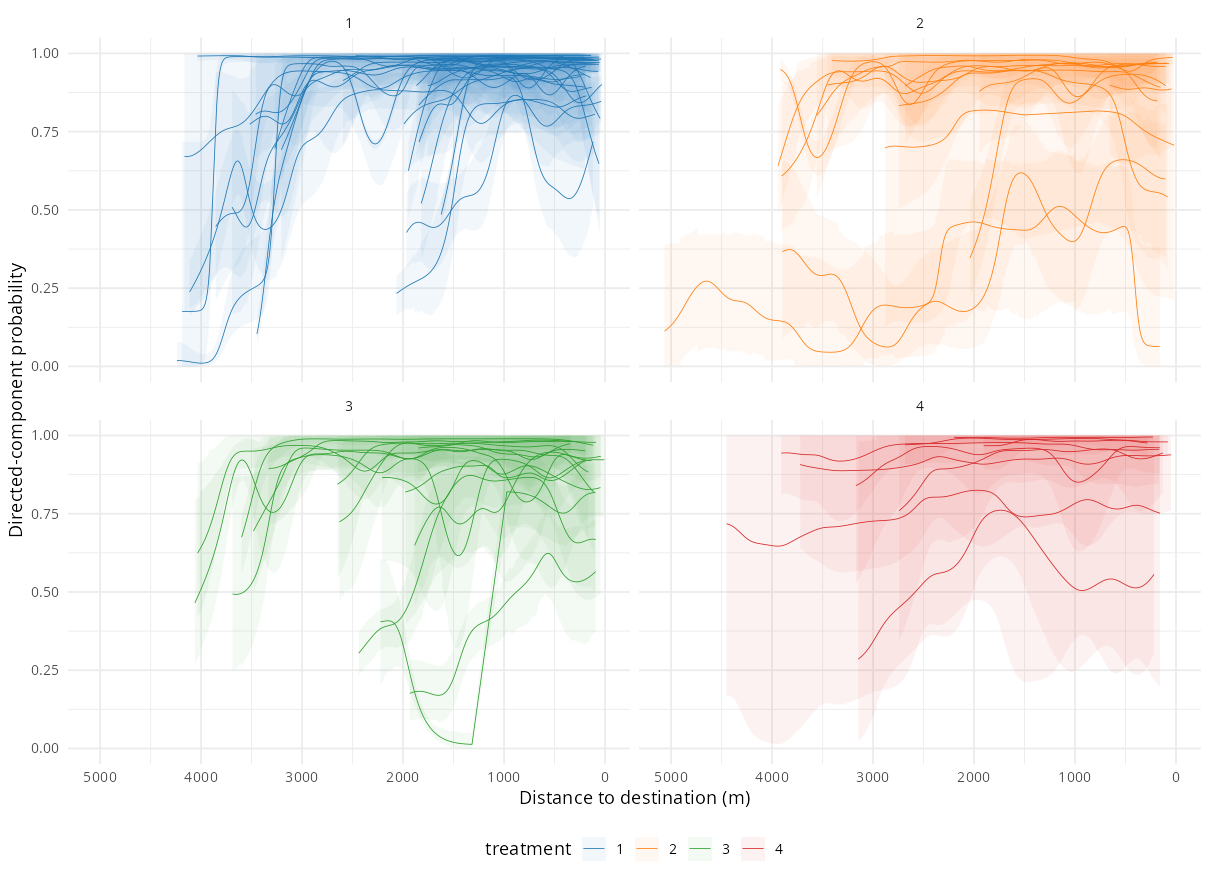

In [61]:
save_figure(p_tag_distance, "p_goal_tag_kernel_distance_faceted_TRUNC", 11, 8)


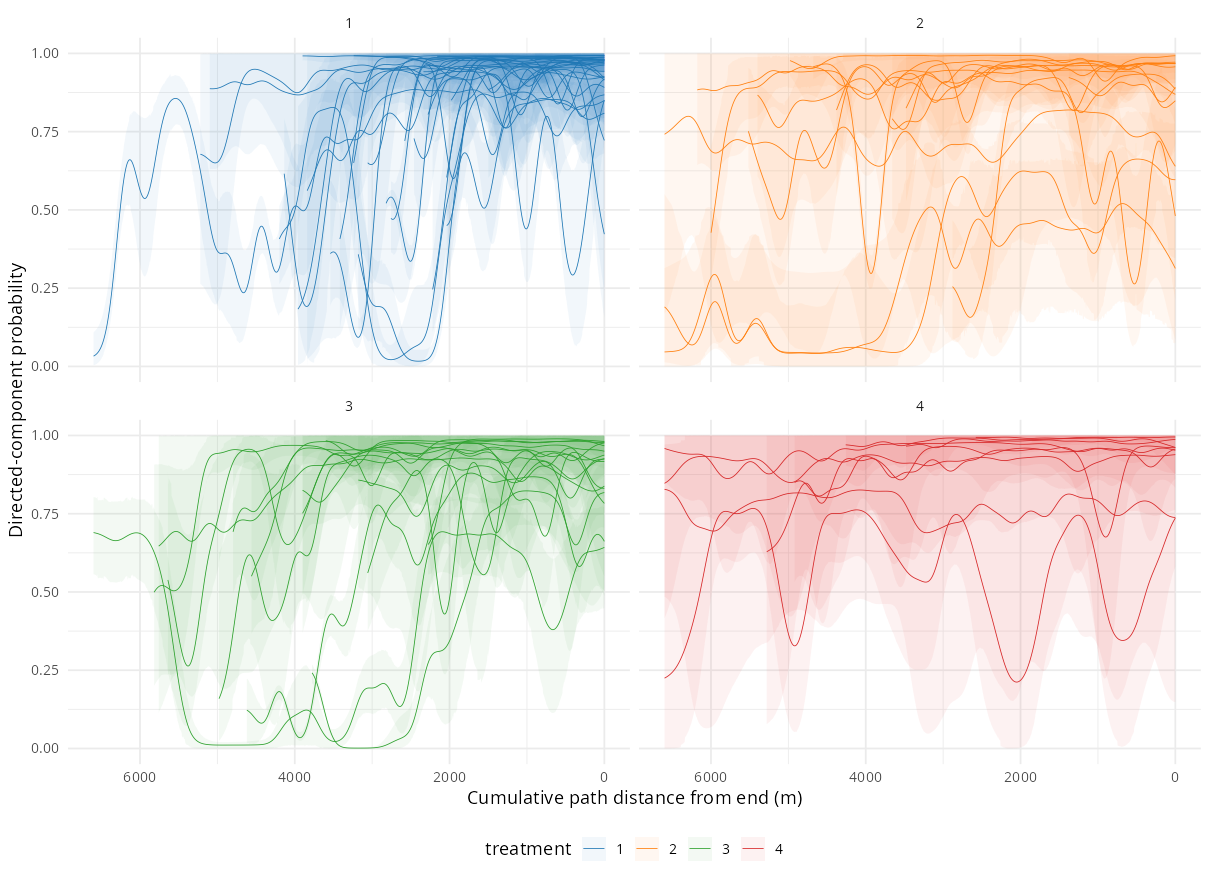

In [62]:
save_figure(p_tag_end, "p_goal_tag_kernel_distFromEndM_faceted_TRUNC", 11, 8)


## Review

The full and quick budgets retain the same data, priors, and model
structure. Review the diagnostic tables and figures above before
interpreting results. The [model guide](../models.md) explains how
direction, precision, and directed-component probability answer
different questions.
